<a href="https://colab.research.google.com/github/NewcomerATL/KASDD-Clustering/blob/main/Model_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 - Life Expectancy: GMM Clustering
**Goal:** Cluster countries by health & socio-economic profile | **Metric:** Silhouette Score

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.mixture import GaussianMixture
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score

sns.set_theme(style="whitegrid", palette="Set2")
PALETTE = {"Developed": "#4C72B0", "Developing": "#DD8452"}

In [ ]:
train = pd.read_csv("train.csv")
print(f"Train shape: {train.shape}")
train.head()

Train shape: (10070, 21)


,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Measles,BMI,under-five deaths,...,GDP,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Hepatitis B,Polio,Diphtheria,Population,HIV/AIDS
0,1967,Developed,75.958705,30.409030,7,16.891705,100.000000,77790,7.022069,10,...,79835.055962,0.633306,0.530616,0.747018,12.774990,0.0,76.0,92.0,64121.0,0.100000
1,1990,Developing,42.915277,101.499444,18,8.230195,0.000000,2106,5.000000,28,...,10.000000,11.396052,11.049630,0.300171,9.982904,100.0,53.0,35.0,2364183.0,4.976989
2,1974,Developing,49.322096,209.702245,81,0.010000,0.000000,0,30.193667,108,...,1766.947595,4.906007,4.736414,0.440699,7.317002,0.0,100.0,100.0,821554.0,0.100000
3,1970,Developing,30.000000,452.548059,168,5.347899,0.000000,29763,10.879758,298,...,1766.947595,11.346782,11.946921,0.677000,12.300000,0.0,83.0,63.0,738541.0,0.100000
4,2010,Developing,61.800000,261.000000,162,1.340000,67.733744,4235,15.600000,243,...,341.399920,11.000000,1.700000,0.401000,8.100000,62.0,69.0,61.0,877267.0,1.700000


## EDA

In [ ]:
# Missing values
missing = train.isnull().sum()
missing_pct = (missing / len(train) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False))

                                 Missing Count  Missing %
Population                                 527       5.23
Hepatitis B                                456       4.53
GDP                                        363       3.60
Total expenditure                          176       1.75
Alcohol                                    150       1.49
Income composition of resources            140       1.39
Schooling                                  137       1.36
BMI                                         23       0.23
thinness  1-19 years                        23       0.23
thinness 5-9 years                          23       0.23
Polio                                       13       0.13
Diphtheria                                  13       0.13
Life expectancy                              8       0.08
Adult Mortality                              8       0.08


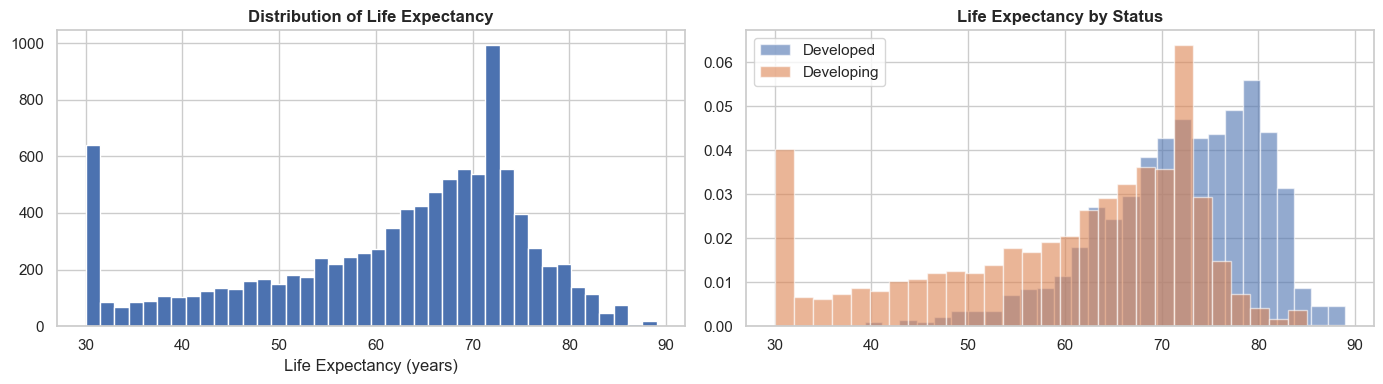

In [ ]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(train["Life expectancy"].dropna(), bins=40, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution of Life Expectancy", fontweight="bold")
axes[0].set_xlabel("Life Expectancy (years)")
for label, grp in train.groupby("Status"):
    axes[1].hist(grp["Life expectancy"].dropna(), bins=30, alpha=0.6, label=label, density=True, color=PALETTE.get(label, "grey"), edgecolor="white")
axes[1].set_title("Life Expectancy by Status", fontweight="bold")
axes[1].legend()
plt.tight_layout(); plt.show()

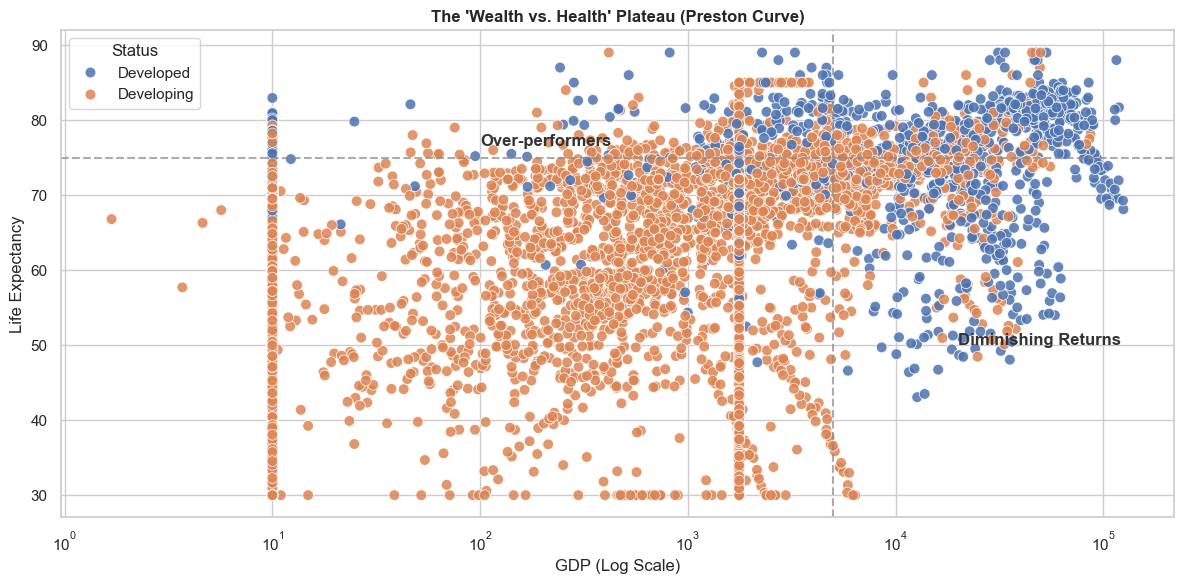

In [ ]:
# Wealth vs. Health Plateau (Preston Curve)
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=train,
    x="GDP",
    y="Life expectancy",
    hue="Status",
    palette=PALETTE,
    edgecolor="white",
    alpha=0.85,
    s=60,
    ax=ax
)

ax.set_xscale("log")
ax.set_title("The 'Wealth vs. Health' Plateau (Preston Curve)", fontweight="bold")
ax.set_xlabel("GDP (Log Scale)"); ax.set_ylabel("Life Expectancy")
ax.axhline(y=75, color="#888888", linestyle="--", alpha=0.7)
ax.axvline(x=5000, color="#888888", linestyle="--", alpha=0.7)
ax.text(100, 76.5, "Over-performers", color="#333333", fontweight="bold")
ax.text(20000, 50, "Diminishing Returns", color="#333333", fontweight="bold")
ax.legend(title="Status")

plt.tight_layout(); plt.show()

## Insight

### Interpretasi data:
- Peningkatan GDP mengakibatkan peningkatan life expectancy. Akan tetapi, kenaikan tersebut mem-plateau. Hal tersebut menunjukkan bahwa terdapat faktor-faktor yang membatasi life expectancy meskipun terdapat uang untuk mendapat fasilitas kesehatan yang baik.
- Terdapat beberapa negara developing dengan GDP yang relatif tinggi tetapi life expectancy yang rendah. Hal tersebut, sekali lagi, menunjukkan bahwa terdapat faktor-faktor lain seperti peperangan atau wabah penyakit yang mempengaruhi life expectancy.
- Terdapat beberapa negara developing dengan GDP rendah tetapi life expectancy yang tinggi dan negara developed dengan GDP tinggi tetapi life expectancy yang rendah. Tingginya life expectancy di negara-negara developing tersebut mengindikasi bahwa negara-negara tersebut kemungkinan memiliki kampanye edukasi kesehatan dan/atau vaksinasi yang sukses serta fasilitas kesehatan yang mendukung sedangkan rendahnya life expectancy di negara-negara developed tersebut mengindikasi bahwa negara-negara tersebut kemungkinan memiliki fasilitas kesehatan yang kurang mendukung dan/atau gaya hidup masyarakat yang kurang sehat.

### Kesimpulan:
Perkembangan ekonomi sangat berdampak pada life expectancy di negara developing. Akan tetapi, bagi negara developed, life expectancy yang tinggi hanya bisa diperoleh dengan gaya hidup yang baik serta fasilitas kesehatan yang bagus dan mudah diakses.

# Data Cleaning

In [ ]:
# Replace pre-1982 Hepatitis B zeros with NaN (disease wasn't tested for yet)
def fill_pre1982_hepatitis(train_df):
    train_df = train_df.copy()
    for df in [train_df]:
        mask = (df["Year"] < 1982) & (df["Hepatitis B"] == 0)
        df.loc[mask, "Hepatitis B"] = np.nan
    return train_df

train_cleaned = fill_pre1982_hepatitis(train)
train_cleaned = train_cleaned.loc[~train_cleaned["Life expectancy"].isna()].reset_index(drop=True)
print(f"Train shape after cleaning: {train_cleaned.shape}")


Train shape after cleaning: (10062, 21)


## Feature Engineering

In [ ]:
def engineer_features(df):
    df = df.copy()

    # Encode Status as binary feature
    df["is_developed"] = (df["Status"] == "Developed").astype(int)

    # Normalize year to capture development trajectory over time
    df["year_norm"] = (df["Year"] - df["Year"].min()) / (df["Year"].max() - df["Year"].min())

    df["immunization_avg"] = (df["Hepatitis B"].fillna(df["Hepatitis B"].median()) +
                          df["Polio"].fillna(df["Polio"].median()) +
                          df["Diphtheria"].fillna(df["Diphtheria"].median())) / 3
    df.drop(columns=["Hepatitis B", "Polio", "Diphtheria"], inplace=True)

    df["mortality_burden"] = df["Adult Mortality"] + np.log1p(df["HIV/AIDS"])

    df["nutrition_gap"] = df["BMI"] - df["thinness  1-19 years"]

    df["human_capital"] = np.log1p(df["GDP"]) * df["Schooling"]

    # Log-transform skewed features
    for raw_col, new_col in [
        ("under-five deaths", "log_under_five_deaths"),
        ("Measles", "log_measles"),
        ("percentage expenditure","log_pct_expenditure"),
        ("HIV/AIDS", "log_hiv"),
        ("GDP", "log_gdp"),
        ("thinness  1-19 years", "log_thinness"),
        ("Alcohol", "log_alcohol"),
        ("Total expenditure", "log_total_expenditure")
    ]:
        if raw_col in df.columns:
            df[new_col] = np.log1p(df[raw_col].clip(0))
            df.drop(columns=[raw_col], inplace=True)

    # Drop unnecessary (already engineered or lacks correlation) columns
    cols_to_drop = ["Population", "thinness 5-9 years", "Year","infant deaths"]
    df.drop(columns=cols_to_drop, inplace=True)

    return df

train_fe = engineer_features(train_cleaned)
print(f"Train: {train_fe.shape}")
print(f"Columns: {list(train_fe.columns)}")

Train: (10062, 20)
Columns: ['Status', 'Life expectancy', 'Adult Mortality', 'BMI', 'Income composition of resources', 'Schooling', 'is_developed', 'year_norm', 'immunization_avg', 'mortality_burden', 'nutrition_gap', 'human_capital', 'log_under_five_deaths', 'log_measles', 'log_pct_expenditure', 'log_hiv', 'log_gdp', 'log_thinness', 'log_alcohol', 'log_total_expenditure']


## Prepare X - Aggregate per Country

In [ ]:
FEATURE_COLS = [c for c in train_fe.columns if c not in ["Status", "Life expectancy"]]
X = train_fe[FEATURE_COLS].values
status_labels = train_fe["Status"].values

print(f"X: {X.shape}  ({len(FEATURE_COLS)} features × {X.shape[0]} observations)")
print(f"Features used: {FEATURE_COLS}")


X: (10062, 18)  (18 features × 10062 observations)
Features used: ['Adult Mortality', 'BMI', 'Income composition of resources', 'Schooling', 'is_developed', 'year_norm', 'immunization_avg', 'mortality_burden', 'nutrition_gap', 'human_capital', 'log_under_five_deaths', 'log_measles', 'log_pct_expenditure', 'log_hiv', 'log_gdp', 'log_thinness', 'log_alcohol', 'log_total_expenditure']


## Optuna Hyperparameter Tuning


In [ ]:
def build_imputer(trial):
    use_knn = trial.suggest_categorical("use_knn", [True, False])
    if use_knn:
        n_neighbors = trial.suggest_int("knn_neighbors", 5, 20)
        return KNNImputer(n_neighbors=n_neighbors)
    else:
        strategy = trial.suggest_categorical("impute_strategy", ["mean", "median"])
        return SimpleImputer(strategy=strategy)

def build_scaler(trial):
    scaler_type = trial.suggest_categorical("scaler", ["standard", "robust"])
    return RobustScaler() if scaler_type == "robust" else StandardScaler()

def objective(trial):
    n_clusters = trial.suggest_int("n_clusters", 2, 10)
    n_components = trial.suggest_int("n_components", 2, 5)
    cov_type = trial.suggest_categorical("cov_type", ["full", "tied", "diag", "spherical"])

    imputer = build_imputer(trial)
    scaler = build_scaler(trial)
    pca = PCA(n_components=n_components, random_state=42)

    # Preprocess
    X_imp = imputer.fit_transform(X)
    X_scaled = scaler.fit_transform(X_imp)
    X_pca = pca.fit_transform(X_scaled)

    # Fit model
    model = GaussianMixture(
        n_components=n_clusters,
        covariance_type=cov_type,
        random_state=42,
        n_init=10)
    model.fit(X_pca)
    labels = model.predict(X_pca)

    if len(np.unique(labels)) < 2:
        return -1.0

    return silhouette_score(X_pca, labels)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=150, show_progress_bar=True)

print(f"Best Silhouette Score : {study.best_value:.4f}")
print(f"Best params : {study.best_params}")


  0%|          | 0/150 [00:00<?, ?it/s]

Best Silhouette Score : 0.7596
Best params : {'n_clusters': 2, 'n_components': 3, 'cov_type': 'tied', 'use_knn': False, 'impute_strategy': 'median', 'scaler': 'robust'}


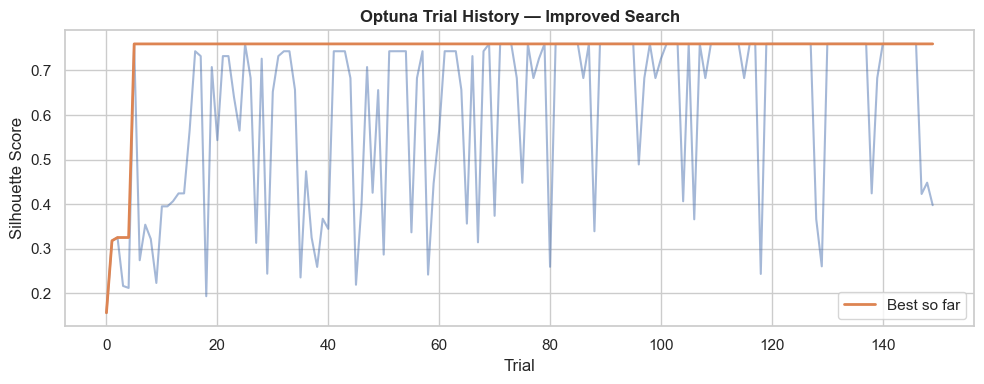

In [ ]:
# Trial history
trial_vals = [t.value for t in study.trials if t.value is not None and t.value > -1]
plt.figure(figsize=(10, 4))
plt.plot(trial_vals, alpha=0.5, color="#4C72B0")
plt.plot(pd.Series(trial_vals).cummax(), color="#DD8452", linewidth=2, label="Best so far")
plt.title("Optuna Trial History — Improved Search", fontweight="bold")
plt.xlabel("Trial"); plt.ylabel("Silhouette Score")
plt.legend(); plt.tight_layout(); plt.show()

## Train Final Pipeline & Evaluate

In [ ]:
best = study.best_params

# Rebuild preprocessing from best params
final_imputer = KNNImputer(n_neighbors=best.get("knn_neighbors", 10))
final_scaler = RobustScaler() if best["scaler"] == "robust" else StandardScaler()
final_pca = PCA(n_components=best["n_components"], random_state=42)

# Preprocess
X_imp = final_imputer.fit_transform(X)
X_scaled = final_scaler.fit_transform(X_imp)
X_pca = final_pca.fit_transform(X_scaled)

# Fit best model
model = GaussianMixture(
    n_components=best["n_clusters"],
    covariance_type=best["cov_type"],
    random_state=42,
    n_init=10
)
model.fit(X_pca)
cluster_labels = model.predict(X_pca)

# Metrics
sil = silhouette_score(X_pca, cluster_labels)
dbi = davies_bouldin_score(X_pca, cluster_labels)

print(f"Final Silhouette Score  : {sil:.4f}")
print(f"Davies-Bouldin Index    : {dbi:.4f}")
print(f"n_clusters              : {best['n_clusters']}")
print(f"n_components (PCA)      : {best['n_components']}")
print(f"Covariance type         : {best['cov_type']}")
print(f"Scaler                  : {best["scaler"]}")
print(f"KNN imputation          : {best.get('use_knn', False)}")
print(f"Features                : {FEATURE_COLS}")


Final Silhouette Score  : 0.7596
Davies-Bouldin Index    : 0.4840
n_clusters              : 2
n_components (PCA)      : 3
Covariance type         : tied
Scaler                  : robust
KNN imputation          : False
Features                : ['Adult Mortality', 'BMI', 'Income composition of resources', 'Schooling', 'is_developed', 'year_norm', 'immunization_avg', 'mortality_burden', 'nutrition_gap', 'human_capital', 'log_under_five_deaths', 'log_measles', 'log_pct_expenditure', 'log_hiv', 'log_gdp', 'log_thinness', 'log_alcohol', 'log_total_expenditure']


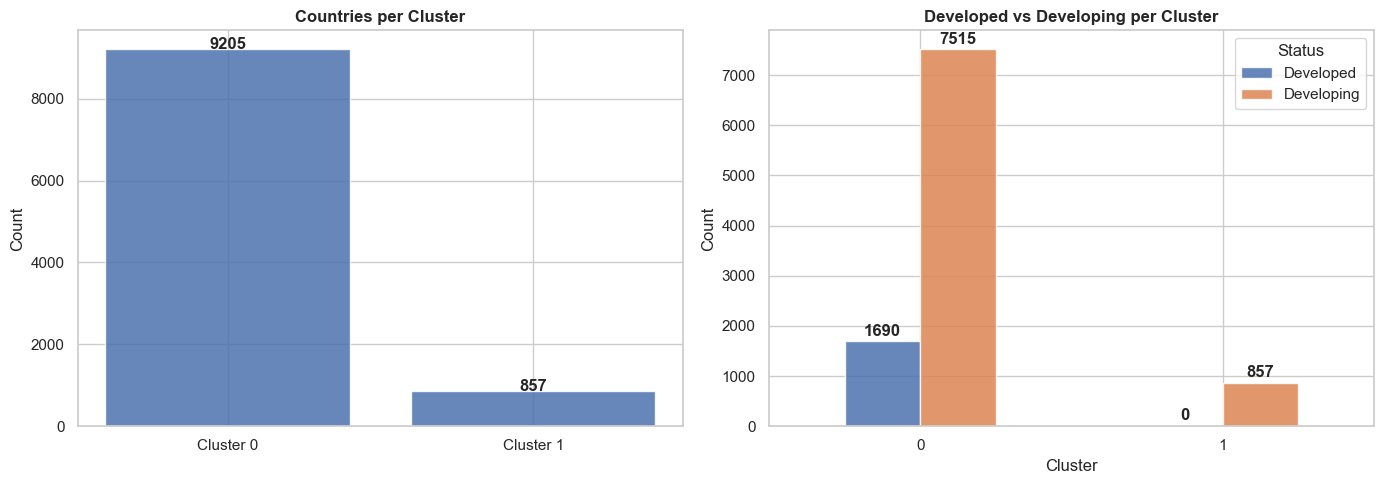

In [ ]:
# Cluster distribution + Developed/Developing crosscheck
train_fe["Cluster"] = cluster_labels
train_fe["Status_label"] = status_labels

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart Countries per Cluster
cluster_counts = train_fe["Cluster"].value_counts().sort_index()
axes[0].bar([f"Cluster {i}" for i in cluster_counts.index], cluster_counts.values, color="#4C72B0", edgecolor="white", alpha=0.85)
for i, v in enumerate(cluster_counts.values):
    axes[0].text(i, v + 0.3, str(v), ha="center", fontweight="bold")
axes[0].set_title("Countries per Cluster", fontweight="bold")
axes[0].set_ylabel("Count")

# Chart Developed vs Developing per Cluster
cross = pd.crosstab(train_fe["Cluster"], train_fe["Status_label"])
cross.plot(kind="bar", ax=axes[1], color=[PALETTE.get(s, "#888888") for s in cross.columns], edgecolor="white", alpha=0.85)
for container in axes[1].containers:
    axes[1].bar_label(container, padding=2, fontweight="bold")
axes[1].set_title("Developed vs Developing per Cluster", fontweight="bold")
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Status")

plt.tight_layout(); plt.show()

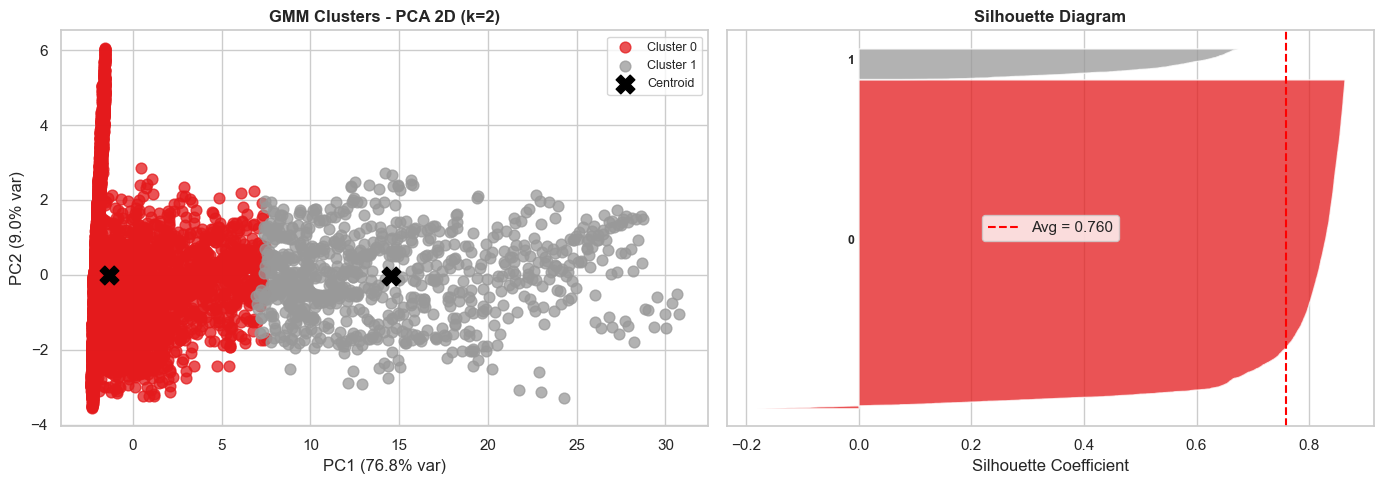

In [ ]:
# PCA 2D visualisation + Silhouette diagram
pca_2d = PCA(n_components=2, random_state=42)
X_vis = pca_2d.fit_transform(X_scaled)
ev = pca_2d.explained_variance_ratio_

sil_vals = silhouette_samples(X_pca, cluster_labels)
K = best["n_clusters"]
cmap_k = plt.cm.get_cmap("Set1", K)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA scatter
for i in range(K):
    mask = cluster_labels == i
    axes[0].scatter(X_vis[mask, 0], X_vis[mask, 1], color=cmap_k(i), s=60, alpha=0.75, label=f"Cluster {i}")

for i in range(K):
    cx = X_vis[cluster_labels == i, 0].mean()
    cy = X_vis[cluster_labels == i, 1].mean()
    axes[0].scatter(cx, cy, c="black", s=180, marker="X", zorder=10)
axes[0].scatter([], [], c="black", s=180, marker="X", label="Centroid")

axes[0].set_title(f"GMM Clusters - PCA 2D (k={K})", fontweight="bold")
axes[0].set_xlabel(f"PC1 ({ev[0]*100:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({ev[1]*100:.1f}% var)")
axes[0].legend(fontsize=9)

# Silhouette diagram
y_lower = 10
for i in range(K):
    vals_i  = np.sort(sil_vals[cluster_labels == i])
    y_upper = y_lower + len(vals_i)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, vals_i, facecolor=cmap_k(i), alpha=0.75)
    axes[1].text(-0.02, y_lower + len(vals_i) / 2, str(i), fontsize=9, fontweight="bold")
    y_lower = y_upper + 10
axes[1].axvline(sil, color="red", linestyle="--", linewidth=1.5, label=f"Avg = {sil:.3f}")
axes[1].set_title("Silhouette Diagram", fontweight="bold")
axes[1].set_xlabel("Silhouette Coefficient"); axes[1].set_yticks([])
axes[1].legend()

plt.tight_layout(); plt.show()

## Cluster Profiling

Mean profile per cluster:
Cluster                               0       1
Life expectancy                   62.93   48.34
Adult Mortality                  221.06  354.77
log_hiv                            0.20    2.48
log_gdp                            5.31    4.76
Schooling                          9.19    7.48
Income composition of resources    0.49    0.36
BMI                               32.39   16.42


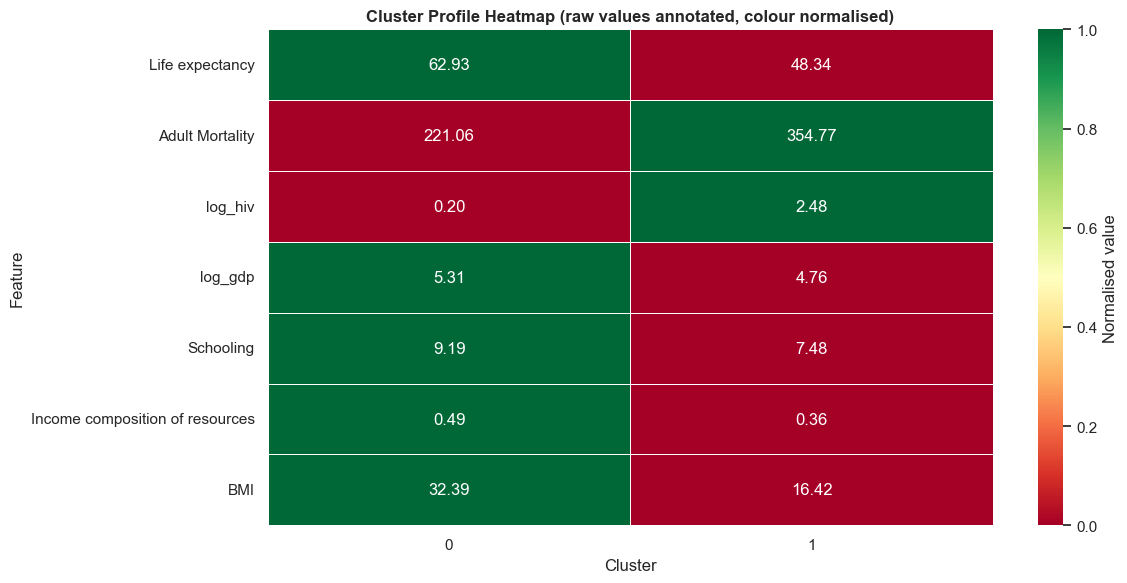

In [ ]:
PROFILE_COLS = [
    "Life expectancy", "Adult Mortality", "log_hiv",
    "log_gdp", "Schooling", "Income composition of resources",
    "Polio", "Diphtheria", "Hepatitis B",
    "BMI", "thinness  1-19 years"
]
PROFILE_COLS = [c for c in PROFILE_COLS if c in train_fe.columns]

profile = train_fe.groupby("Cluster")[PROFILE_COLS].mean().round(2)
print("Mean profile per cluster:")
print(profile.T.to_string())

# Heatmap (normalised values, raw numbers annotated)
profile_norm = (profile - profile.min()) / (profile.max() - profile.min() + 1e-9)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(profile_norm.T, annot=profile.T, fmt=".2f", cmap="RdYlGn", linewidths=0.5, ax=ax, cbar_kws={"label": "Normalised value"})
ax.set_title("Cluster Profile Heatmap (raw values annotated, colour normalised)", fontweight="bold")
ax.set_xlabel("Cluster"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

# Analisis Clustering (BisectingKMeans + Alternatif)
Notebook ini mengikuti best-practices: preprocessing (duplicate and missing values, outliers, encoding, scaling), pemilihan jumlah cluster (Elbow & Silhouette), pemodelan BisectingKMeans, alternatif (DBSCAN, Agglomerative), evaluasi dan visualisasi (PCA).

In [ ]:
# 0) Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder
from sklearn.cluster import KMeans, BisectingKMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 200)


In [ ]:
try:
    csv_path = 'train.csv'
    df = pd.read_csv(csv_path)
except:
    csv_path = '/kaggle/input/datasets/raymundowoloblo/life-expectancy-kasdd-genap-20252026/train.csv'
    df = pd.read_csv(csv_path)

##  EDA (One Specific Question)
Apakah negara dengan percentage expenditure yang tinggi selalu memiliki Life expectancy yang lebih baik, atau terdapat titik jenuh di mana penambahan biaya tidak lagi meningkatkan harapan hidup secara signifikan?"

(Fokus: Analisis efisiensi biaya dan kemungkinan adanya hukum hasil yang semakin berkurang)


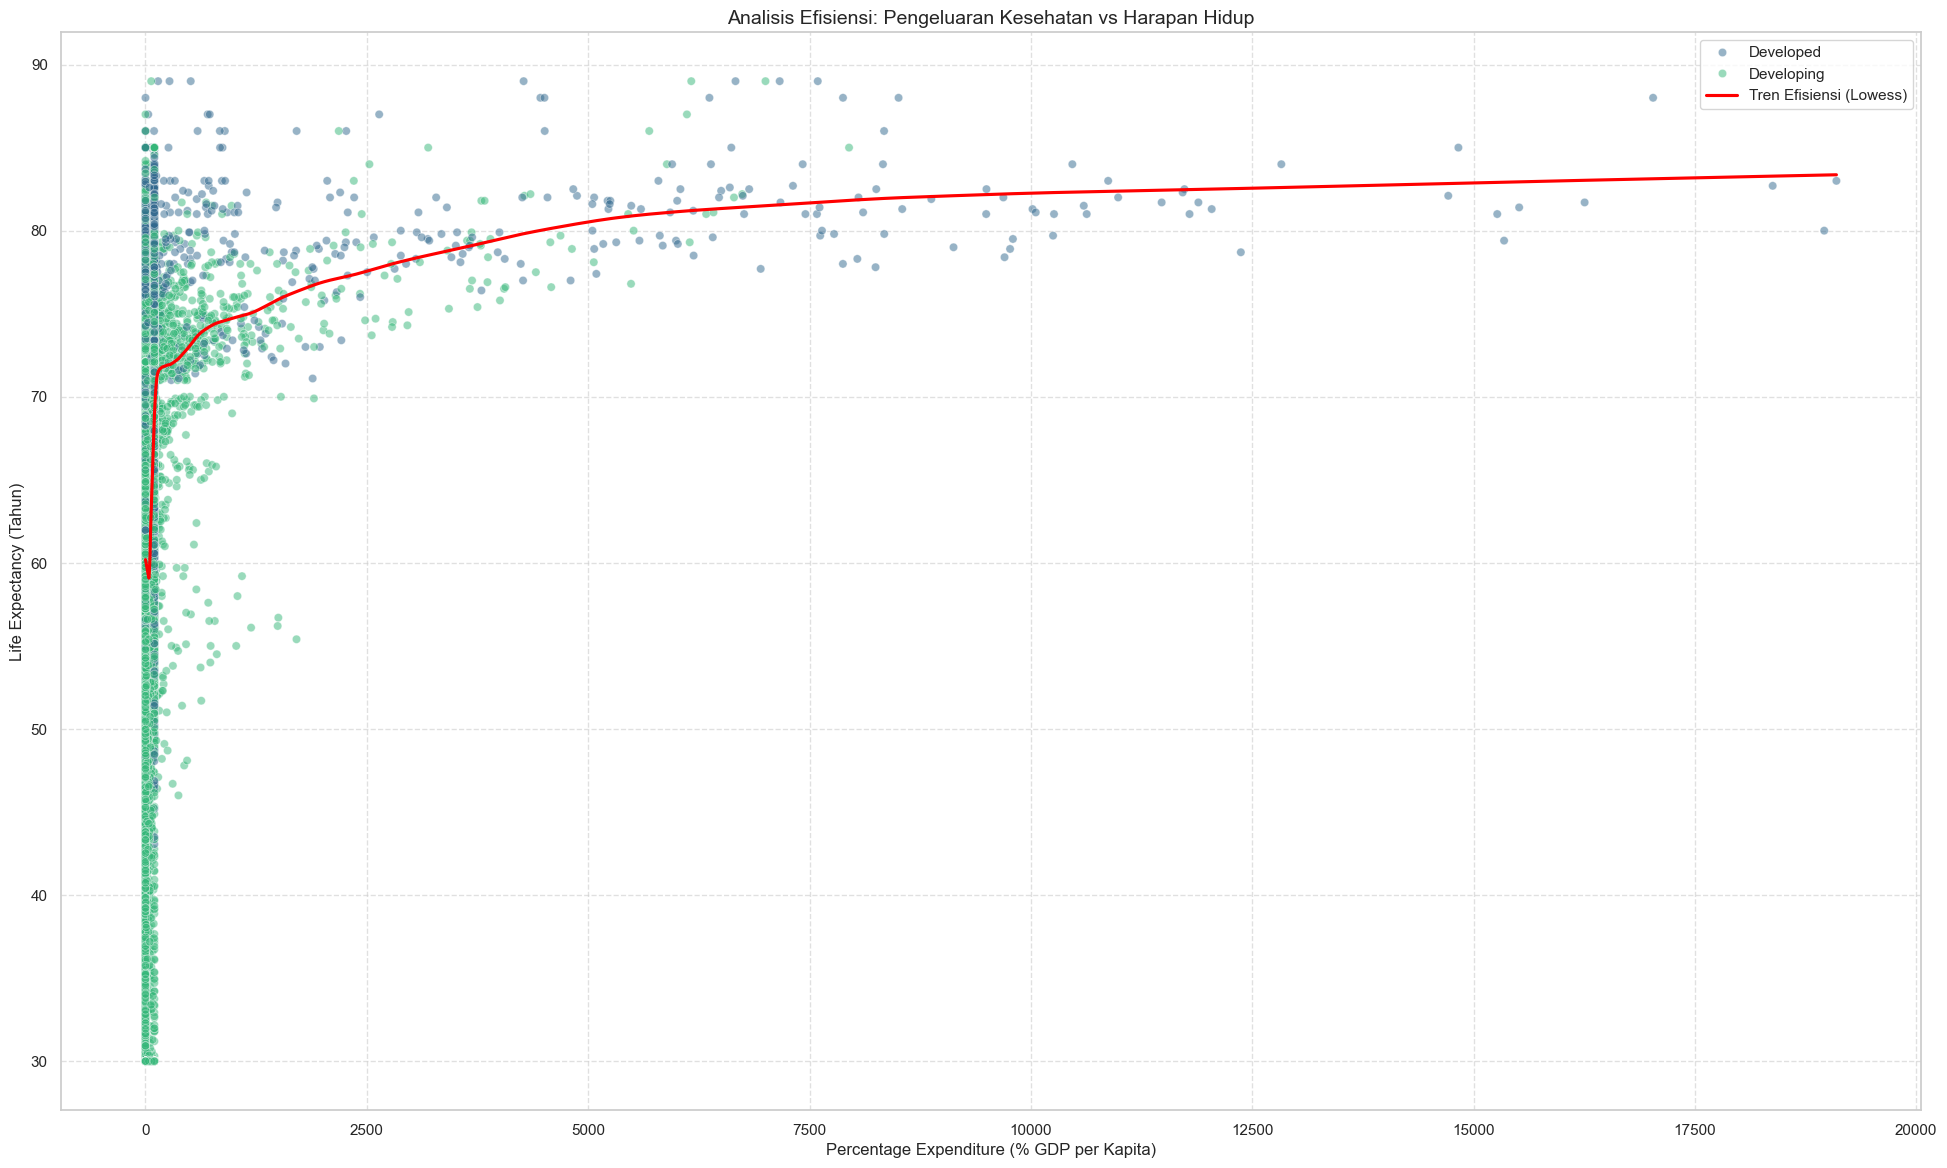

Korelasi Spearman antara Pengeluaran dan Harapan Hidup: 0.40


In [ ]:
# Filter data untuk menghindari nilai nol yang bisa merusak visualisasi logaritmik jika diperlukan
df_clean = df.dropna(subset=['percentage expenditure', 'Life expectancy'])

plt.figure(figsize=(24, 14))

# 1. Scatter plot dengan warna berdasarkan Status negara
sns.scatterplot(
    data=df_clean,
    x='percentage expenditure',
    y='Life expectancy',
    hue='Status',
    alpha=0.5,
    palette='viridis'
)

# 2. Menambahkan garis tren LOWESS untuk melihat pola titik jenuh (diminishing returns)
sns.regplot(
    data=df_clean,
    x='percentage expenditure',
    y='Life expectancy',
    scatter=False,
    lowess=True,
    color='red',
    label='Tren Efisiensi (Lowess)'
)

plt.title('Analisis Efisiensi: Pengeluaran Kesehatan vs Harapan Hidup', fontsize=14)
plt.xlabel('Percentage Expenditure (% GDP per Kapita)', fontsize=12)
plt.ylabel('Life Expectancy (Tahun)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

# 3. Analisis Tambahan: Korelasi Spearman
# Menggunakan Spearman karena hubungan mungkin tidak linear (melengkung)
correlation = df_clean[['percentage expenditure', 'Life expectancy']].corr(method='spearman').iloc[0, 1]
print(f"Korelasi Spearman antara Pengeluaran dan Harapan Hidup: {correlation:.2f}")


#### Penjelasan Logika Analisis:

1. Garis LOWESS (Red Line):
    
    Garis ini sangat penting untuk pertanyaan di atas. Jika garis tersebut mulai mendatar di sisi kanan (saat pengeluaran semakin tinggi), itu menunjukkan adanya titik jenuh. Artinya, menambah biaya kesehatan tidak lagi memberikan peningkatan harapan hidup yang signifikan.

2. Korelasi Spearman:

    Kita menggunakan Spearman (bukan Pearson) karena metode ini lebih baik dalam menangkap hubungan monotonic yang tidak harus garis lurus (linear), sangat cocok untuk melihat tren efisiensi.

3. Segmentasi Status:

    Memisahkan Developed dan Developing membantu melihat apakah negara berkembang mendapatkan "keuntungan" kesehatan yang lebih besar dari setiap dollar yang dikeluarkan dibandingkan negara maju.

#### Interpretasi Grafik & Korelasi

1. Fenomena Diminishing Returns (Hukum Hasil yang Menurun):

    Garis merah (Lowess) naik sangat tajam di awal (pengeluaran rendah), namun mulai melandai secara signifikan setelah melewati angka pengeluaran sekitar 2.500–5.000. Ini artinya, bagi negara miskin, sedikit tambahan biaya kesehatan berdampak besar pada nyawa manusia. Namun bagi negara kaya, menambah biaya besar hanya memberikan sedikit tambahan umur.

2. Korelasi Spearman (0.40):

    Angka 0.40 menunjukkan hubungan positif yang moderat/sedang. Hubungan ini tidak mencapai 0.8 atau 0.9 karena adanya variabilitas yang tinggi. Banyak negara dengan pengeluaran rendah memiliki rentang harapan hidup yang sangat lebar (dari 40 hingga 80 tahun), menunjukkan bahwa uang (GDP) bukan satu-satunya faktor penentu kesehatan.

3. Pemisahan Status:

    Titik hijau (Developing) menumpuk di sisi kiri bawah, sementara titik biru (Developed) menyebar di bagian atas dan kanan. Hal ini mengonfirmasi bahwa negara maju cenderung berada di area "titik jenuh" di mana pengeluaran mereka tinggi namun peningkatan harapan hidupnya sudah stabil di angka 80+ tahun.

--- ANALISIS TITIK JENUH ---
Efisiensi mulai menurun drastis pada pengeluaran: sekitar 3119.35 USD


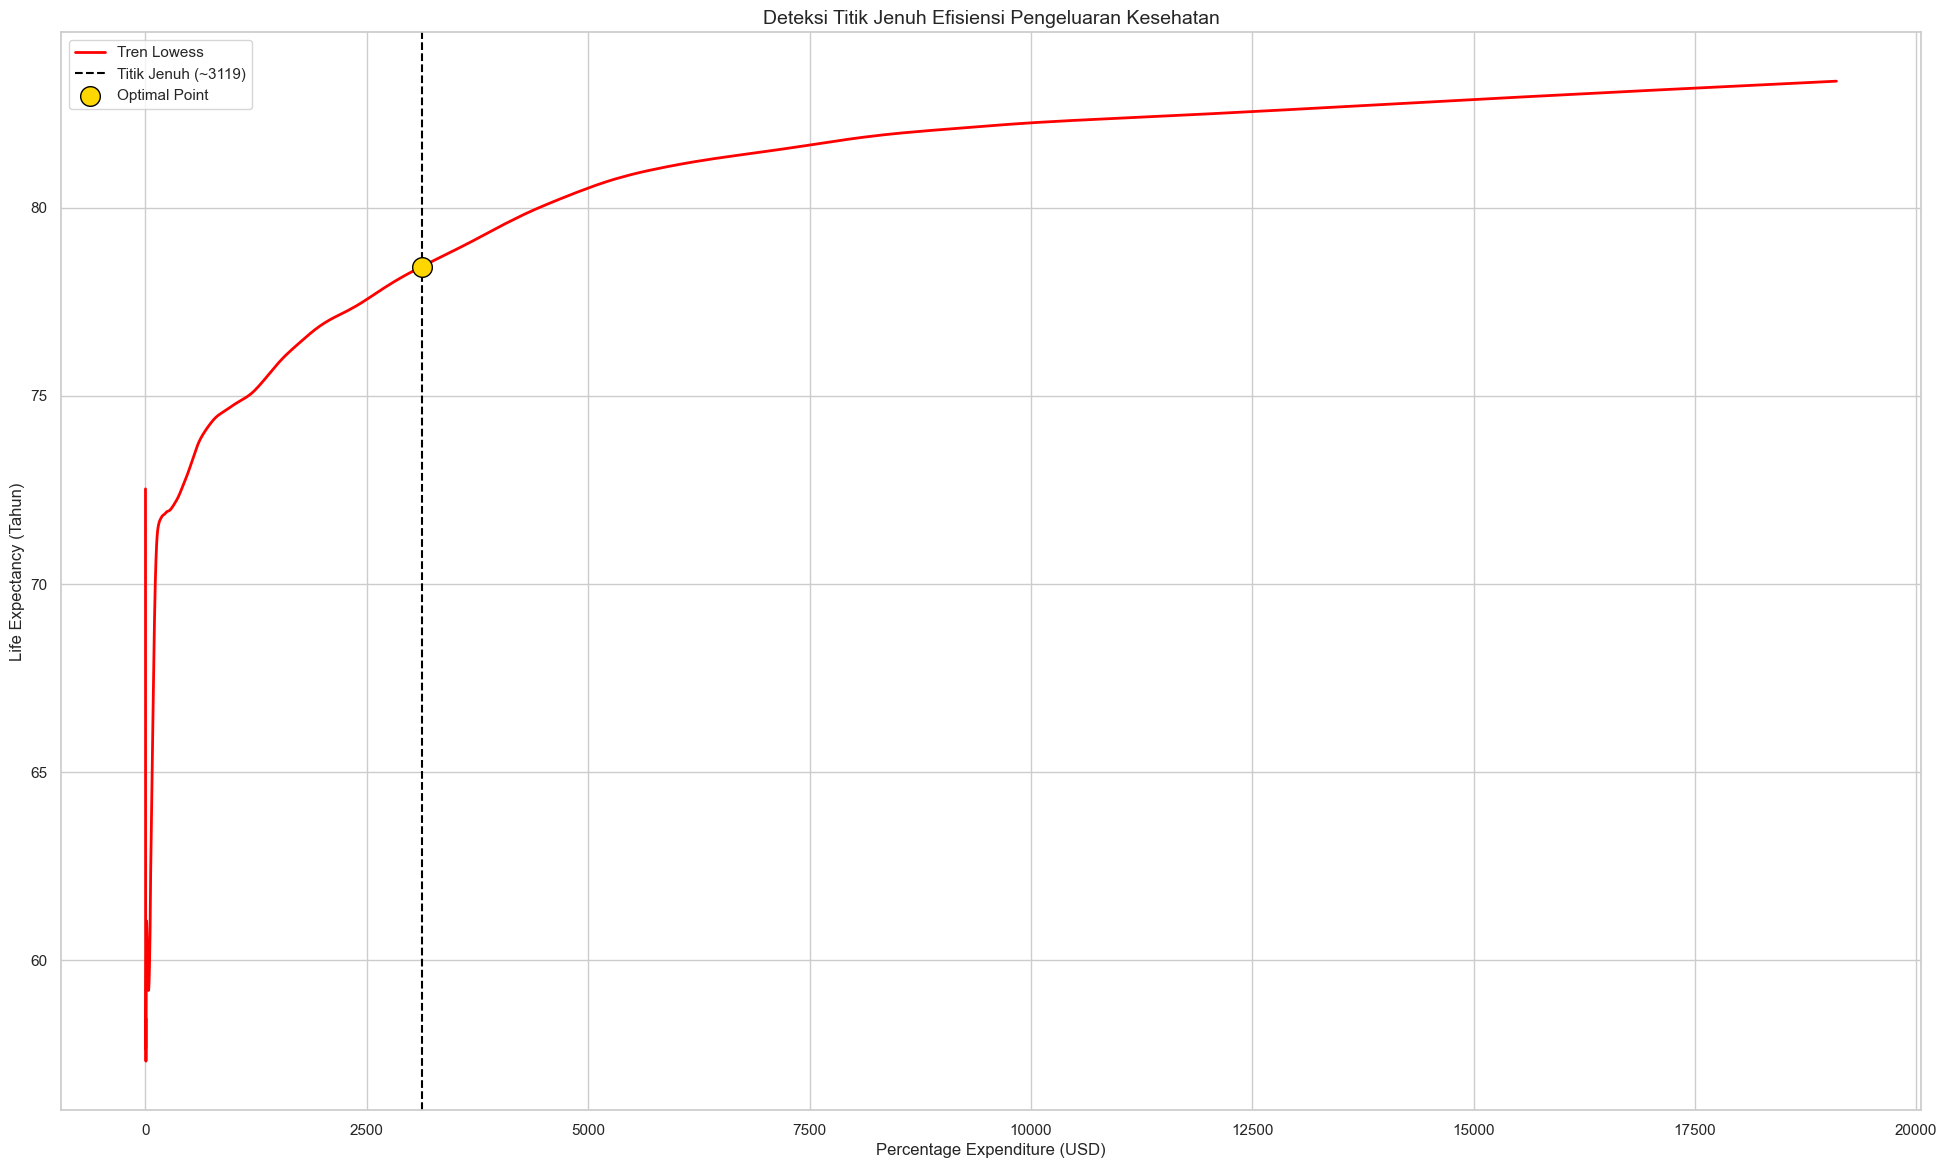

In [ ]:
from kneed import KneeLocator

# 1. Mengambil data smooth dari garis Lowess untuk perhitungan matematis
# Kita perlu mengekstrak titik-titik dari model lowess
# 1. Gunakan frac yang lebih besar agar garis lebih smooth (menghilangkan noise di angka 0)
from statsmodels.nonparametric.smoothers_lowess import lowess
z = lowess(df_clean['Life expectancy'], df_clean['percentage expenditure'], frac=0.5)
x_smooth = z[:, 0]
y_smooth = z[:, 1]

# 2. Filter data smooth: Kita hanya mencari titik jenuh setelah pengeluaran > 50 USD
# Ini untuk menghindari noise di angka 0 yang merusak deteksi
mask = x_smooth > 50
x_filtered = x_smooth[mask]
y_filtered = y_smooth[mask]

# 3. Mencari Titik Jenuh (Knee Point): Jalankan KneeLocator pada data yang sudah difilter
# S=1.0 adalah sensitivitas, curve='concave' karena bentuk grafiknya melengkung ke bawah
kn = KneeLocator(x_filtered, y_filtered, S=1.0, curve='concave', direction='increasing')
knee_point = kn.knee

print(f"--- ANALISIS TITIK JENUH ---")
print(f"Efisiensi mulai menurun drastis pada pengeluaran: sekitar {knee_point:.2f} USD")

# 4. Visualisasi Titik Jenuh pada Grafik
plt.figure(figsize=(24, 14))
plt.plot(x_smooth, y_smooth, color='red', label='Tren Lowess', linewidth=2)
if knee_point:
    plt.axvline(x=knee_point, color='black', linestyle='--', label=f'Titik Jenuh (~{knee_point:.0f})')
    plt.scatter(knee_point, kn.knee_y, color='gold', s=200, edgecolors='black', zorder=5, label='Optimal Point')

plt.title('Deteksi Titik Jenuh Efisiensi Pengeluaran Kesehatan', fontsize=14)
plt.xlabel('Percentage Expenditure (USD)', fontsize=12)
plt.ylabel('Life Expectancy (Tahun)', fontsize=12)
plt.legend()
# plt.grid(True, alpha=0.3)
plt.show()


1. Ekstraksi Tren:

    Kode ini mengambil data "garis merah" dari grafik sebelumnya dan mengubahnya menjadi koordinat angka.
    
2. Knee Detection:
    
    Menggunakan algoritma Knee Point untuk menemukan area di mana kemiringan (slope) berubah dari sangat curam menjadi mulai mendatar.
    
3. Kesimpulan Bisnis/Data:
    
    Titik yang dihasilkan (sekitar 3100 USD) adalah angka "Investasi Terbaik". Di titik ini, negara mendapatkan peningkatan usia maksimal sebelum biaya per tahunnya menjadi terlalu mahal untuk kenaikan yang sedikit.

## 1) Data Preprocessing & Cleaning
Langkah-langkah: inspeksi, missing values, duplikasi, outliers (sebelum scaling), encoding kolom kategorikal, scaling fitur.

In [ ]:
# 1.1) Load dataset (sesuaikan path bila perlu)
print('Reading:', csv_path)
print('Shape:', df.shape)
df.head()

Reading: train.csv
Shape: (10070, 21)


,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Measles,BMI,under-five deaths,Total expenditure,GDP,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Hepatitis B,Polio,Diphtheria,Population,HIV/AIDS
0,1967,Developed,75.958705,30.409030,7,16.891705,100.000000,77790,7.022069,10,20.000000,79835.055962,0.633306,0.530616,0.747018,12.774990,0.0,76.0,92.0,64121.0,0.100000
1,1990,Developing,42.915277,101.499444,18,8.230195,0.000000,2106,5.000000,28,3.613611,10.000000,11.396052,11.049630,0.300171,9.982904,100.0,53.0,35.0,2364183.0,4.976989
2,1974,Developing,49.322096,209.702245,81,0.010000,0.000000,0,30.193667,108,6.405683,1766.947595,4.906007,4.736414,0.440699,7.317002,0.0,100.0,100.0,821554.0,0.100000
3,1970,Developing,30.000000,452.548059,168,5.347899,0.000000,29763,10.879758,298,0.000000,1766.947595,11.346782,11.946921,0.677000,12.300000,0.0,83.0,63.0,738541.0,0.100000
4,2010,Developing,61.800000,261.000000,162,1.340000,67.733744,4235,15.600000,243,6.860000,341.399920,11.000000,1.700000,0.401000,8.100000,62.0,69.0,61.0,877267.0,1.700000


In [ ]:
# 1.2) Quick inspection
print('--- Info ---')
df.info()
print('--- Describe (numeric) ---')
display(df.describe().T)
print('--- Describe (all) ---')
display(df.describe(include='all').T)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             10070 non-null  int64  
 1   Status                           10070 non-null  str    
 2   Life expectancy                  10062 non-null  float64
 3   Adult Mortality                  10062 non-null  float64
 4   infant deaths                    10070 non-null  int64  
 5   Alcohol                          9920 non-null   float64
 6   percentage expenditure           10070 non-null  float64
 7   Measles                          10070 non-null  int64  
 8   BMI                              10047 non-null  float64
 9   under-five deaths                10070 non-null  int64  
 10  Total expenditure                9894 non-null   float64
 11  GDP                              9707 non-null   float64
 12  thinness  1-19 y

,count,mean,std,min,25%,50%,75%,max
Year,10070.0,1.982327e+03,1.890324e+01,1950.00000,1966.000000,1982.000000,1.998000e+03,2.015000e+03
Life expectancy,10062.0,6.168606e+01,1.420348e+01,30.00000,53.705956,65.740650,7.210000e+01,8.900000e+01
Adult Mortality,10062.0,2.324526e+02,2.138724e+02,1.00000,93.082183,171.279919,3.000214e+02,1.000000e+03
infant deaths,10070.0,5.213684e+01,2.557956e+02,0.00000,0.000000,4.000000,2.900000e+01,4.840000e+03
Alcohol,9920.0,5.786028e+00,6.134692e+00,0.01000,0.646448,3.970000,8.741190e+00,3.000000e+01
percentage expenditure,10070.0,1.961027e+02,1.003055e+03,0.00000,0.000000,0.000000,1.000000e+02,1.909905e+04
Measles,10070.0,7.723835e+03,3.423361e+04,0.00000,0.000000,35.000000,2.480000e+03,6.388990e+05
BMI,10047.0,3.106347e+01,2.372595e+01,1.00000,6.771506,26.100000,4.990000e+01,8.730000e+01
under-five deaths,10070.0,7.637110e+01,3.609292e+02,0.00000,0.000000,5.000000,4.100000e+01,6.968000e+03
Total expenditure,9894.0,5.321350e+00,4.252678e+00,0.00000,2.385204,4.850228,7.100000e+00,2.000000e+01


--- Describe (all) ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,10070.0,NaN,NaN,NaN,1982.32711,18.903239,1950.0,1966.0,1982.0,1998.0,2015.0
Status,10070,2,Developing,8380,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Life expectancy,10062.0,NaN,NaN,NaN,61.686064,14.20348,30.0,53.705956,65.74065,72.1,89.0
Adult Mortality,10062.0,NaN,NaN,NaN,232.45265,213.872367,1.0,93.082183,171.279919,300.021382,1000.0
infant deaths,10070.0,NaN,NaN,NaN,52.136842,255.795622,0.0,0.0,4.0,29.0,4840.0
Alcohol,9920.0,NaN,NaN,NaN,5.786028,6.134692,0.01,0.646448,3.97,8.74119,30.0
percentage expenditure,10070.0,NaN,NaN,NaN,196.102675,1003.054608,0.0,0.0,0.0,100.0,19099.04506
Measles,10070.0,NaN,NaN,NaN,7723.834955,34233.607978,0.0,0.0,35.0,2480.0,638899.0
BMI,10047.0,NaN,NaN,NaN,31.063474,23.72595,1.0,6.771506,26.1,49.9,87.3
under-five deaths,10070.0,NaN,NaN,NaN,76.371102,360.929173,0.0,0.0,5.0,41.0,6968.0


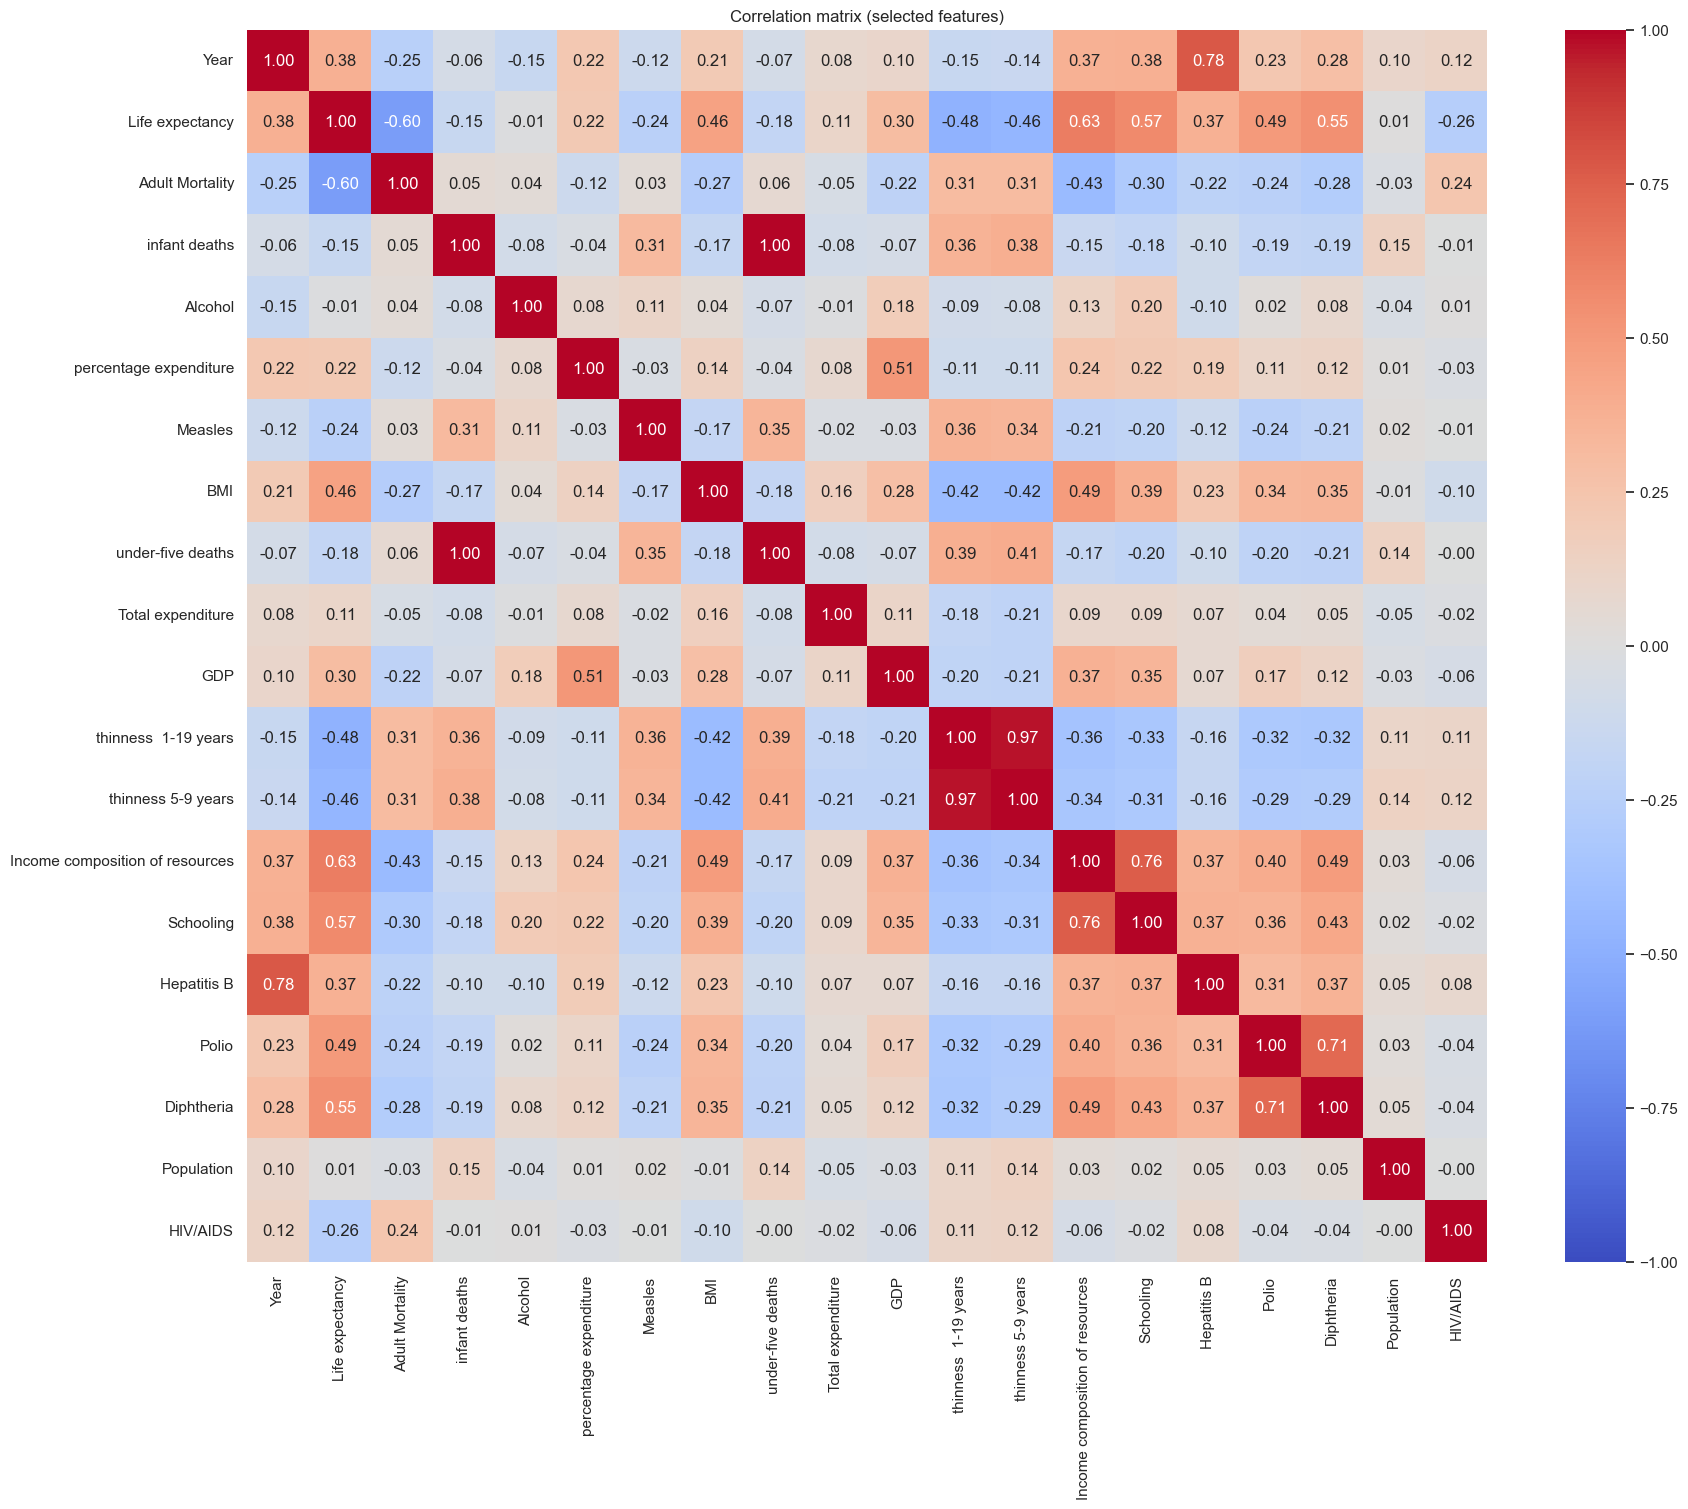

In [ ]:
# Correlation heatmap for selected numeric features
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()  # Automatically select numeric columns
corr_df = df[num_cols].apply(pd.to_numeric, errors='coerce').corr()
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (selected features)')
plt.show()

Deskripsi semua kolom:
- `Year`: Tahun pengamatan data (1950-2015).
- `Population`: Jumlah populasi negara.
- `Life expectancy`: Harapan hidup dalam satuan tahun.
- `Adult Mortality`: Tingkat kematian dewasa (rentang usia 15-60 tahun) per 1000 populasi.
- `infant deaths`: Jumlah kematian bayi per 1000 populasi.
- `under-five deaths`: Jumlah kematian anak di bawah 5 tahun per 1000 populasi.
- `HIV/AIDS`: Kematian akibat HIV/AIDS per 1000 kelahiran hidup (usia 0-4 tahun).
- `Measles`: Jumlah kasus penyakit campak yang dilaporkan per 1000 populasi.
- `Hepatitis B`: Persentase cakupan imunisasi Hepatitis B pada anak usia 1 tahun (%).
- `Polio`: Persentase cakupan imunisasi Polio pada anak usia 1 tahun (%).
- `Diphtheria`: Persentase cakupan imunisasi DTP3 (Difteri-Tetanus-Pertusis) pada anak usia 1 tahun (%).
- `Alcohol`: Konsumsi alkohol per kapita (liter alkohol murni per orang dengan usia 15+ tahun).
- `BMI`: Body Mass Index rata-rata populasi.
- `thinness 1-19 years`: Prevalensi kekurusan pada remaja usia 10-19 tahun (%).
- `thinness 5-9 years`: Prevalensi kekurusan pada anak usia 5-9 tahun (%).
- `GDP`: Gross Domestic Product per kapita dalam USD.
- `percentage expenditure`: Pengeluaran kesehatan sebagai persentase dari GDP per kapita (%).
- `Total expenditure`: Pengeluaran kesehatan pemerintah sebagai persentase dari total pengeluaran pemerintah (%).
- `Schooling`: Rata-rata lama sekolah atau pendidikan dalam satuan tahun.
- `Income composition of resources`: Indeks Human Development Index dalam hal komposisi pendapatan sumber daya (menggunakan skala 0-1).

In [ ]:
# 1.3) Missing values overview
missing_values = df.isna().sum().reset_index()
missing_values.columns = ['feature', 'missing_count']
missing_values['percentage'] = (missing_values['missing_count'] / len(df)) * 100
print("Kolom dengan Missing Values:")
display(missing_values)

Kolom dengan Missing Values:


,feature,missing_count,percentage
0,Year,0,0.000000
1,Status,0,0.000000
2,Life expectancy,8,0.079444
3,Adult Mortality,8,0.079444
4,infant deaths,0,0.000000
5,Alcohol,150,1.489573
6,percentage expenditure,0,0.000000
7,Measles,0,0.000000
8,BMI,23,0.228401
9,under-five deaths,0,0.000000


In [ ]:
# 1.4) Remove duplicate rows (recommended)
print('Before dupes:', df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print('After dupes:', df.shape)

Before dupes: (10070, 21)
After dupes: (10070, 21)


### Handling missing values
Pilihan: drop rows/columns atau imputasi. Di bawah ini disediakan opsi parameter untuk dijalankan (imputasi numeric dengan median/mean, kategori dengan modus).

In [ ]:
# 1.5) Missing-value handling (pilih opsi)
missing_strategy = 'impute'  # 'impute' atau 'drop_rows'
impute_strategy = 'median'   # 'mean' atau 'median'

df_mv = df.copy()
num_cols = df_mv.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_mv.select_dtypes(include=['object','category']).columns.tolist()
print('Numeric cols:', num_cols)
print('Categorical cols:', cat_cols)

if missing_strategy == 'drop_rows':
    df_mv = df_mv.dropna().reset_index(drop=True)
else:
    if num_cols:
        imputer_num = SimpleImputer(strategy=impute_strategy)
        df_mv[num_cols] = imputer_num.fit_transform(df_mv[num_cols])
    if cat_cols:
        imputer_cat = SimpleImputer(strategy='most_frequent')
        df_mv[cat_cols] = imputer_cat.fit_transform(df_mv[cat_cols])

print('After missing handling shape:', df_mv.shape)
print("Missing values: ", df_mv.isnull().sum().sum())

Numeric cols: ['Year', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS']
Categorical cols: ['Status']
After missing handling shape: (10070, 21)
Missing values:  0


### Features Creation and Selection
Buat fitur baru (weighted berdasarkan korelasi dengan `Life expectancy`). Lalu, hapus fitur lama yang digunakan untuk membuat fitur baru tadi

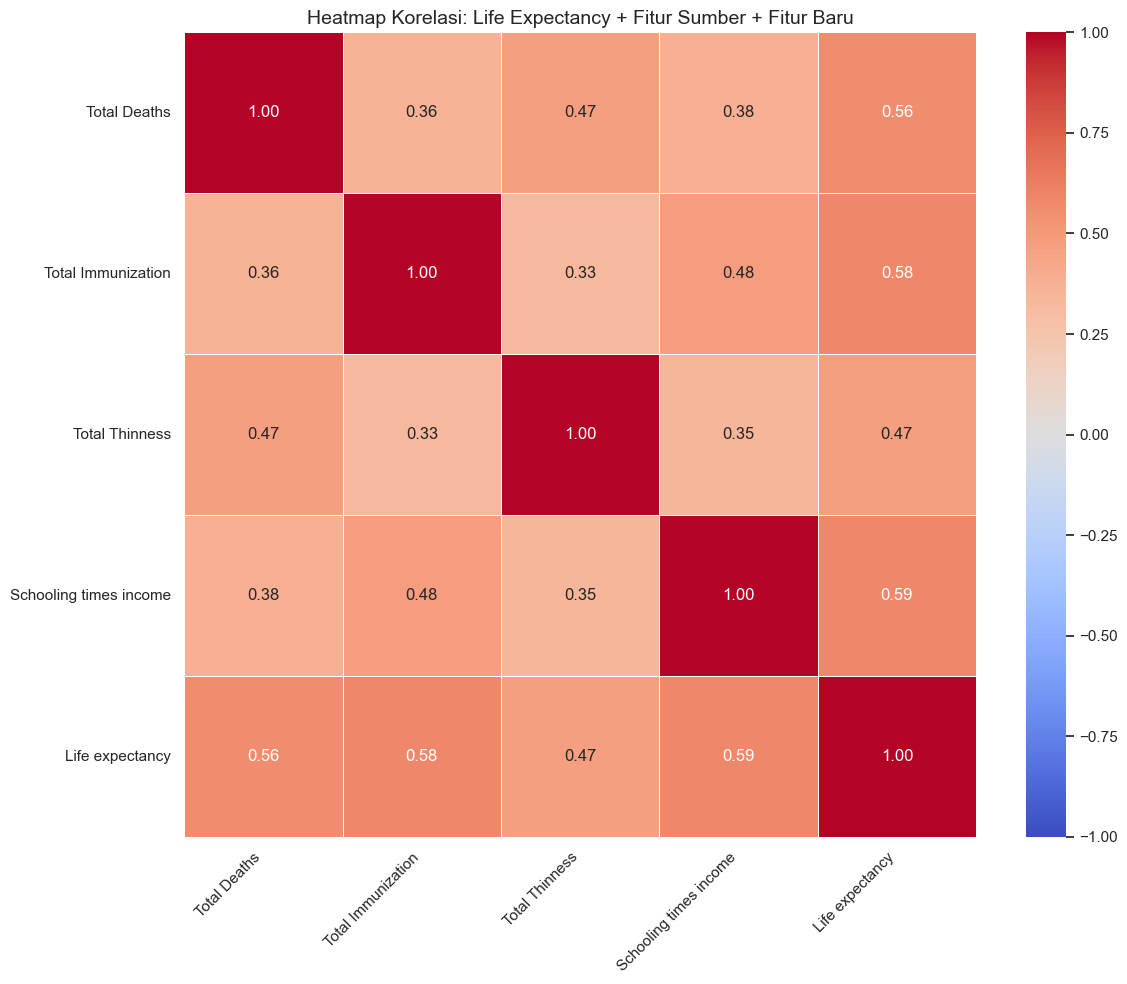

In [ ]:
# Feature Engineering pada df_fc
# Buat fitur baru (weighted berdasarkan korelasi dengan `Life expectancy`). Lalu, hapus fitur lama yang digunakan untuk membuat fitur baru tadi
df_fc = df_mv.copy()

# Total Deaths = (infant deaths + under-five deaths + Adult Mortality) dengan bobot korelasi masing-masing terhadap Life expectancy
a_1 = df_fc['infant deaths'].corr(df_fc['Life expectancy'])
a_2 = df_fc['under-five deaths'].corr(df_fc['Life expectancy'])
a_3 = df_fc['Adult Mortality'].corr(df_fc['Life expectancy'])
df_fc['Total Deaths'] = a_1 * df_fc['infant deaths'] + a_2 * df_fc['under-five deaths'] + a_3 * df_fc['Adult Mortality']

# Total Immunization = Penjumlahan dari Hepatitis B, Polio, dan Diphtheria dengan bobot korelasi masing-masing terhadap Life expectancy
b_1 = df_fc['Hepatitis B'].corr(df_fc['Life expectancy'])
b_2 = df_fc['Polio'].corr(df_fc['Life expectancy'])
b_3 = df_fc['Diphtheria'].corr(df_fc['Life expectancy'])
df_fc['Total Immunization'] = b_1 * df_fc['Hepatitis B'] + b_2 * df_fc['Polio'] + b_3 * df_fc['Diphtheria']

# Total Thinness = Penjumlahan dari thinness  1-19 years dan thinness 5-9 years dengan bobot korelasi masing-masing terhadap Life expectancy
c_1 = df_fc['thinness  1-19 years'].corr(df_fc['Life expectancy'])
c_2 = df_fc['thinness 5-9 years'].corr(df_fc['Life expectancy'])
df_fc['Total Thinness'] = c_1 * df_fc['thinness  1-19 years'] + c_2 * df_fc['thinness 5-9 years']

# Schooling + Income = penjumlahan antara Schooling dan Income composition of resources dengan bobot korelasi masing-masing terhadap Life expectancy
d_1 = df_fc['Schooling'].corr(df_fc['Life expectancy'])
d_2 = df_fc['Income composition of resources'].corr(df_fc['Life expectancy'])
df_fc['Schooling times income'] = d_1 * df_fc['Schooling'] * d_2 * df_fc['Income composition of resources']

old_features = ['infant deaths', 'under-five deaths', 'Adult Mortality',
                'Hepatitis B', 'Polio', 'Diphtheria',
                'thinness  1-19 years', 'thinness 5-9 years',
                'Schooling', 'Income composition of resources']

new_features = ['Total Deaths', 'Total Immunization', 'Total Thinness', 'Schooling times income']

df_fc = df_fc.drop(columns=old_features)

# Pastikan kolom target tersedia untuk korelasi
df_corr = df_fc.copy()
df_corr['Life expectancy'] = df_corr['Life expectancy'].reset_index(drop=True)

# Kolom yang relevan untuk heatmap
cols_heatmap = new_features + ['Life expectancy']  # Hanya tampilkan fitur baru dan target

# # Jika ingin melihat hasilnya
# display(df_fc[cols_heatmap].head())

corr_mat = df_corr[cols_heatmap].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi: Life Expectancy + Fitur Sumber + Fitur Baru', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Handling outliers (PENTING: sebelum scaling)
Disarankan: deteksi outlier (IQR atau z-score). Pilih apakah menghapus baris outlier atau melakukan capping (winsorizing).

In [ ]:
# 1.6) Outlier detection & handling
df_out = df_fc.copy()
num_cols = df_out.select_dtypes(include=[np.number]).columns.tolist()
print(num_cols)

print("Skewness before: ")
skews = df_out[num_cols].skew()
display(skews)

outlier_method = 'iqr'   # 'iqr' atau 'zscore'
outlier_action = 'cap'  # 'remove' atau 'cap'

if outlier_method == 'iqr':
    Q1 = df_out[num_cols].quantile(0.25)
    Q3 = df_out[num_cols].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    mask = ~((df_out[num_cols] < lower) | (df_out[num_cols] > upper)).any(axis=1)
    if outlier_action == 'remove':
        df_out = df_out[mask].reset_index(drop=True)
    else:
        df_out[num_cols] = df_out[num_cols].clip(lower=lower, upper=upper, axis=1)
else:
    try:
        from scipy import stats
    except Exception:
        stats = None
        print('scipy not available: zscore method tidak bisa digunakan')
    if stats is None:
        raise ImportError('scipy diperlukan untuk metode zscore')
    zscores = np.abs(stats.zscore(df_out[num_cols], nan_policy='omit'))
    mask = (zscores < 3).all(axis=1)
    if outlier_action == 'remove':
        df_out = df_out[mask].reset_index(drop=True)
    else:
        means = df_out[num_cols].mean()
        stds = df_out[num_cols].std()
        lower = means - 3*stds
        upper = means + 3*stds
        df_out[num_cols] = df_out[num_cols].clip(lower=lower, upper=upper, axis=1)

print("\nSkewness After: ")
skews = df_out[num_cols].skew()
display(skews)

print('Shape before outlier handling:', df_mv.shape)
print('Shape after outlier handling:', df_out.shape)

['Year', 'Life expectancy', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'Total expenditure', 'GDP', 'Population', 'HIV/AIDS', 'Total Deaths', 'Total Immunization', 'Total Thinness', 'Schooling times income']
Skewness before: 


Year                       0.009627
Life expectancy           -0.815732
Alcohol                    1.435809
percentage expenditure     9.758529
Measles                   10.466883
BMI                        0.529969
Total expenditure          1.243076
GDP                        4.811734
Population                27.471928
HIV/AIDS                   8.171452
Total Deaths              -3.983066
Total Immunization        -0.581801
Total Thinness            -2.379169
Schooling times income     0.522632
dtype: float64


Skewness After: 


Year                      0.009627
Life expectancy          -0.815732
Alcohol                   1.072907
percentage expenditure    1.529577
Measles                   1.213398
BMI                       0.529969
Total expenditure         0.630699
GDP                       1.074215
Population                1.164320
HIV/AIDS                  1.219662
Total Deaths             -0.985199
Total Immunization       -0.581801
Total Thinness           -1.073544
Schooling times income    0.516699
dtype: float64

Shape before outlier handling: (10070, 21)
Shape after outlier handling: (10070, 15)


### Encoding kolom kategorikal
Strategi: One-Hot untuk cardinality rendah, Label Encoding untuk cardinality tinggi.

In [ ]:
# 1.7) Encoding kategorikal
df_enc = df_fc.copy()
cat_cols = df_enc.select_dtypes(include=['object','category']).columns.tolist()
print('Found categorical columns:', cat_cols)
for col in cat_cols:
    nunique = df_enc[col].nunique()
    if nunique <= 10:
        df_enc = pd.get_dummies(df_enc, columns=[col], prefix=[col], drop_first=False)
    else:
        le = LabelEncoder()
        df_enc[col] = le.fit_transform(df_enc[col].astype(str))

print('After encoding shape:', df_enc.shape)

Found categorical columns: ['Status']
After encoding shape: (10070, 16)


In [ ]:
df_enc.info()

<class 'pandas.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    10070 non-null  float64
 1   Life expectancy         10070 non-null  float64
 2   Alcohol                 10070 non-null  float64
 3   percentage expenditure  10070 non-null  float64
 4   Measles                 10070 non-null  float64
 5   BMI                     10070 non-null  float64
 6   Total expenditure       10070 non-null  float64
 7   GDP                     10070 non-null  float64
 8   Population              10070 non-null  float64
 9   HIV/AIDS                10070 non-null  float64
 10  Total Deaths            10070 non-null  float64
 11  Total Immunization      10070 non-null  float64
 12  Total Thinness          10070 non-null  float64
 13  Schooling times income  10070 non-null  float64
 14  Status_Developed        10070 non-null  bool   
 

In [ ]:
# Mapping kolom bertipe boolean ke 0 dan 1
bool_cols = df_enc.select_dtypes(include=['bool']).columns.tolist()
for col in bool_cols:
    df_enc[col] = df_enc[col].astype(int)

### Feature Scaling (pilih dan jelaskan berdasarkan distribusi)
Pilihan umum: `StandardScaler` jika fitur mendekati distribusi normal; `MinMaxScaler` jika fitur ber-range terbatas atau sangat skewed. Kita gunakan heuristik sederhana untuk memilih.

In [ ]:
# 1.8) Heuristik pemilihan scaler dan scaling
num_cols = df_enc.select_dtypes(include=[np.number]).columns.tolist()
print(num_cols)

print("\nSebelum scaling: ")
scaling_verification = pd.DataFrame({
    'Feature': df_enc.columns,
    'Mean': df_enc.mean(),
    'Std': df_enc.std()
})
display(scaling_verification)

print("Skewness before: ")
skews = df_enc[num_cols].skew()
display(skews)

# # Heuristic: jika >50% fitur memiliki skew < 0.75, gunakan StandardScaler, lain MinMax
# threshold = 1
# if (skews.abs() < threshold).mean() >= 0.5:
#     scaler = StandardScaler()
#     chosen = 'StandardScaler'
# else:
#     scaler = MinMaxScaler()
#     chosen = 'MinMaxScaler'

# print('\nChosen scaler heuristic:', chosen, "\n")

scaler = RobustScaler()

X_num = df_enc[num_cols].values
X_scaled = scaler.fit_transform(X_num)
df_scaled = pd.DataFrame(X_scaled, columns=num_cols, index=df_enc.index)

# Verifikasi scaling
print("\nVerifikasi Scaling (Mean ≈ 0, Std ≈ 1):")
scaling_verification = pd.DataFrame({
    'Feature': df_scaled.columns,
    'Mean': df_scaled.mean(),
    'Std': df_scaled.std()
})
display(scaling_verification)

print("Skewness after: ")
skews = df_scaled[num_cols].skew()
display(skews)

['Year', 'Life expectancy', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'Total expenditure', 'GDP', 'Population', 'HIV/AIDS', 'Total Deaths', 'Total Immunization', 'Total Thinness', 'Schooling times income', 'Status_Developed', 'Status_Developing']

Sebelum scaling: 


,Feature,Mean,Std
Year,Year,1.982327e+03,1.890324e+01
Life expectancy,Life expectancy,6.168929e+01,1.419830e+01
Alcohol,Alcohol,5.758977e+00,6.092799e+00
percentage expenditure,percentage expenditure,1.961027e+02,1.003055e+03
Measles,Measles,7.723835e+03,3.423361e+04
BMI,BMI,3.105214e+01,2.370002e+01
Total expenditure,Total expenditure,5.313115e+00,4.215799e+00
GDP,GDP,4.154423e+03,1.195856e+04
Population,Population,5.810642e+06,2.932908e+07
HIV/AIDS,HIV/AIDS,1.706509e+00,7.537902e+00


Skewness before: 


Year                       0.009627
Life expectancy           -0.815732
Alcohol                    1.435809
percentage expenditure     9.758529
Measles                   10.466883
BMI                        0.529969
Total expenditure          1.243076
GDP                        4.811734
Population                27.471928
HIV/AIDS                   8.171452
Total Deaths              -3.983066
Total Immunization        -0.581801
Total Thinness            -2.379169
Schooling times income     0.522632
Status_Developed           1.777974
Status_Developing         -1.777974
dtype: float64


Verifikasi Scaling (Mean ≈ 0, Std ≈ 1):


,Feature,Mean,Std
Year,Year,0.010222,0.590726
Life expectancy,Life expectancy,-0.220336,0.772184
Alcohol,Alcohol,0.225726,0.768764
percentage expenditure,percentage expenditure,1.961027,10.030546
Measles,Measles,3.100337,13.803874
BMI,BMI,0.115046,0.550589
Total expenditure,Total expenditure,0.100815,0.918182
GDP,GDP,2.268579,6.806438
Population,Population,2.355810,13.848591
HIV/AIDS,HIV/AIDS,9.491193,44.533635


Skewness after: 


Year                       0.009627
Life expectancy           -0.815732
Alcohol                    1.435809
percentage expenditure     9.758529
Measles                   10.466883
BMI                        0.529969
Total expenditure          1.243076
GDP                        4.811734
Population                27.471928
HIV/AIDS                   8.171452
Total Deaths              -3.983066
Total Immunization        -0.581801
Total Thinness            -2.379169
Schooling times income     0.522632
Status_Developed           1.777974
Status_Developing         -1.777974
dtype: float64

In [ ]:
# Keep any non-numeric columns for reference (not used for clustering)
non_num = [c for c in df_enc.columns if c not in num_cols]
print(non_num)

if non_num:
    df_scaled_full = pd.concat([df_scaled, df_enc[non_num]], axis=1)
else:
    df_scaled_full = df_scaled

print('Scaled shape (numeric only):', df_scaled.shape)

[]
Scaled shape (numeric only): (10070, 16)


## 2) Penentuan Jumlah Cluster (Evaluasi Awal)
Gunakan Elbow (Inertia) dan Silhouette Score untuk validasi. Jalankan sel-sel berikut untuk range K yang default 1-10.

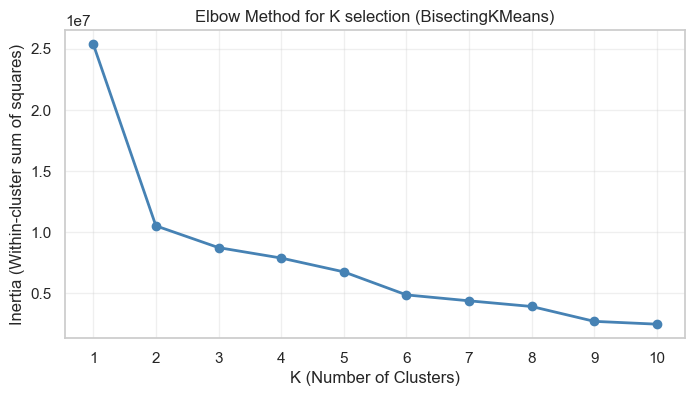

BisectingKMeans uses hierarchical bisecting approach for efficient clustering.


In [ ]:
# 2.1) Elbow method (Inertia) dengan BisectingKMeans
inertia = []
K_range = range(1, 11)
X = df_scaled_full.select_dtypes(include=[np.number]).values
for k in K_range:
    bkm = BisectingKMeans(n_clusters=k, random_state=42, n_init=10)
    bkm.fit(X)
    inertia.append(bkm.inertia_)

plt.figure(figsize=(8,4))
plt.plot(list(K_range), inertia, marker='o', color='steelblue', linewidth=2)
plt.xlabel('K (Number of Clusters)')
plt.ylabel('Inertia (Within-cluster sum of squares)')
plt.title('Elbow Method for K selection (BisectingKMeans)')
plt.xticks(list(K_range))
plt.grid(True, alpha=0.3)
plt.show()

print('BisectingKMeans uses hierarchical bisecting approach for efficient clustering.')


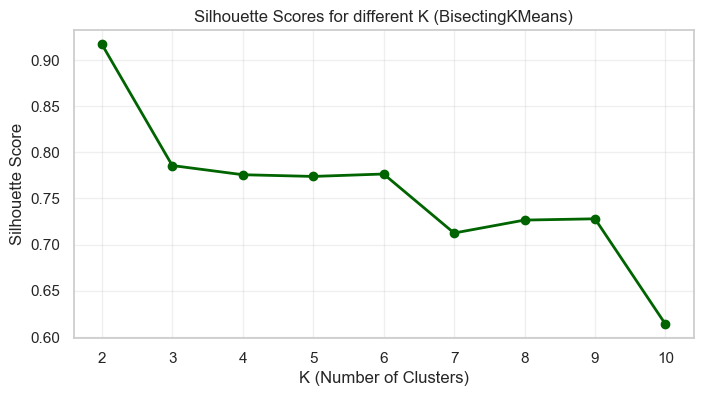

Best K by silhouette score (BisectingKMeans): 2
Best silhouette score: 0.9174


In [ ]:
# 2.2) Silhouette score (k=2..10) dengan BisectingKMeans
sil_scores = []
K_range2 = range(2, 11)
for k in K_range2:
    bkm = BisectingKMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = bkm.fit_predict(X)
    score = silhouette_score(X, labels_k)
    sil_scores.append(score)

plt.figure(figsize=(8,4))
plt.plot(list(K_range2), sil_scores, marker='o', color='darkgreen', linewidth=2)
plt.xlabel('K (Number of Clusters)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for different K (BisectingKMeans)')
plt.xticks(list(K_range2))
plt.grid(True, alpha=0.3)
plt.show()

best_k = K_range2[np.argmax(sil_scores)]
print(f'Best K by silhouette score (BisectingKMeans): {best_k}')
print(f'Best silhouette score: {max(sil_scores):.4f}')


## 3) Model Clustering
Implementasi BisectingKMeans (hierarchical variant of KMeans) sebagai metode utama, dan contoh alternatif (KMeans standar, DBSCAN, Agglomerative untuk perbandingan).


In [ ]:
# 3.1) Fit BisectingKMeans dengan K terpilih (atur K jika perlu)
K = int(best_k)  # ubah secara manual jika ingin override
bkm = BisectingKMeans(n_clusters=K, random_state=42, n_init=10)
labels = bkm.fit_predict(X)
df_result = df_scaled_full.copy()
df_result['cluster'] = labels

print(f'BisectingKMeans Clustering Results (K={K}):')
print(f'Inertia: {bkm.inertia_:.4f}')
print(f'Silhouette Score: {silhouette_score(X, labels):.4f}')
print('\nCluster counts:')
print(df_result['cluster'].value_counts().sort_index())


BisectingKMeans Clustering Results (K=2):
Inertia: 10527607.5961
Silhouette Score: 0.9174

Cluster counts:
cluster
0     167
1    9903
Name: count, dtype: int64


In [ ]:
# 3.2) Cluster centers (kembali ke skala asli untuk interpretasi)
centers_scaled = bkm.cluster_centers_
centers_orig = scaler.inverse_transform(centers_scaled)
centers_df = pd.DataFrame(centers_orig, columns=num_cols)
print('Cluster Centers (BisectingKMeans) - Original Scale:')
display(centers_df)


Cluster Centers (BisectingKMeans) - Original Scale:


,Year,Life expectancy,Alcohol,percentage expenditure,Measles,BMI,Total expenditure,GDP,Population,HIV/AIDS,Total Deaths,Total Immunization,Total Thinness,Schooling times income,Status_Developed,Status_Developing
0,1991.592814,39.111425,5.727443,49.734229,4609.880240,20.939799,5.493108,695.190994,5.811705e+06,51.737099,-387.941696,85.578197,-10.702626,1.464917,-8.326673e-17,1.000000
1,1982.170857,62.070029,5.759509,198.570971,7776.347369,31.222667,5.310080,4212.758215,5.810624e+06,0.862814,-158.795792,81.906174,-5.627262,1.918182,1.706554e-01,0.829345


In [ ]:
# 3.3) KMeans Standar - untuk perbandingan dengan BisectingKMeans
km_compare = KMeans(n_clusters=K, random_state=42, n_init=10)
km_labels = km_compare.fit_predict(X)
km_sil = silhouette_score(X, km_labels)

print('--- Model Comparison ---')
print(f'BisectingKMeans (K={K}):')
print(f'  Inertia: {bkm.inertia_:.4f}')
print(f'  Silhouette: {silhouette_score(X, labels):.4f}')
print()
print(f'KMeans Standar (K={K}):')
print(f'  Inertia: {km_compare.inertia_:.4f}')
print(f'  Silhouette: {km_sil:.4f}')
print()

--- Model Comparison ---
BisectingKMeans (K=2):
  Inertia: 10527607.5961
  Silhouette: 0.9174

KMeans Standar (K=2):
  Inertia: 10527607.5961
  Silhouette: 0.9174



### Perbandingan dengan Alternatif Model
Contoh: KMeans standar, DBSCAN (density-based), dan AgglomerativeClustering (hierarchical) untuk referensi perbandingan.


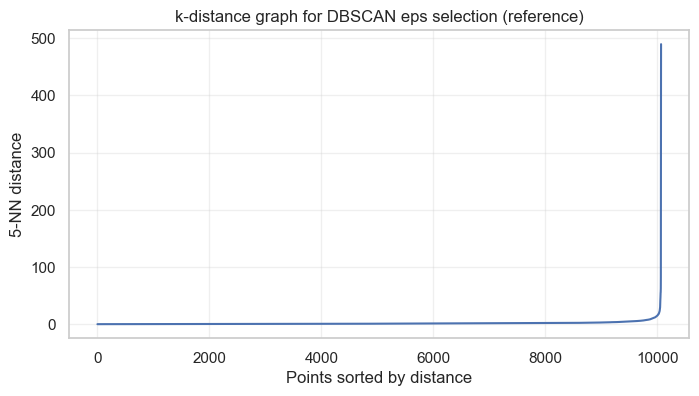

DBSCAN unique labels (incl noise=-1): [-1]


In [ ]:
# Optional: DBSCAN example untuk referensi
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, 4])
plt.figure(figsize=(8,4))
plt.plot(distances)
plt.ylabel('5-NN distance')
plt.xlabel('Points sorted by distance')
plt.title('k-distance graph for DBSCAN eps selection (reference)')
plt.grid(True, alpha=0.3)
plt.show()

# coba DBSCAN dengan eps contoh
db = DBSCAN(eps=0.5, min_samples=44)  # min_samples biasanya = 2*dimensi atau 4, sesuaikan dengan dataset
db_labels = db.fit_predict(X)
print('DBSCAN unique labels (incl noise=-1):', np.unique(db_labels))


In [ ]:
# 3.4) Agglomerative Clustering - untuk perbandingan hierarchical
ac = AgglomerativeClustering(n_clusters=K, linkage='ward')
ac_labels = ac.fit_predict(X)
ac_sil = silhouette_score(X, ac_labels)
print('Agglomerative Clustering (K={}, linkage=ward):'.format(K))
print('  Silhouette Score: {:.4f}'.format(ac_sil))
print('  Cluster counts:')
print(pd.Series(ac_labels).value_counts().sort_index())


Agglomerative Clustering (K=2, linkage=ward):
  Silhouette Score: 0.9022
  Cluster counts:
0     239
1    9831
Name: count, dtype: int64


## 4) Evaluasi Internal & Visualisasi (BisectingKMeans)
Tampilkan Elbow & Silhouette (sudah di atas), Silhouette per-sample, PCA 2D/3D untuk visualisasi, dan ringkasan karakteristik tiap cluster.


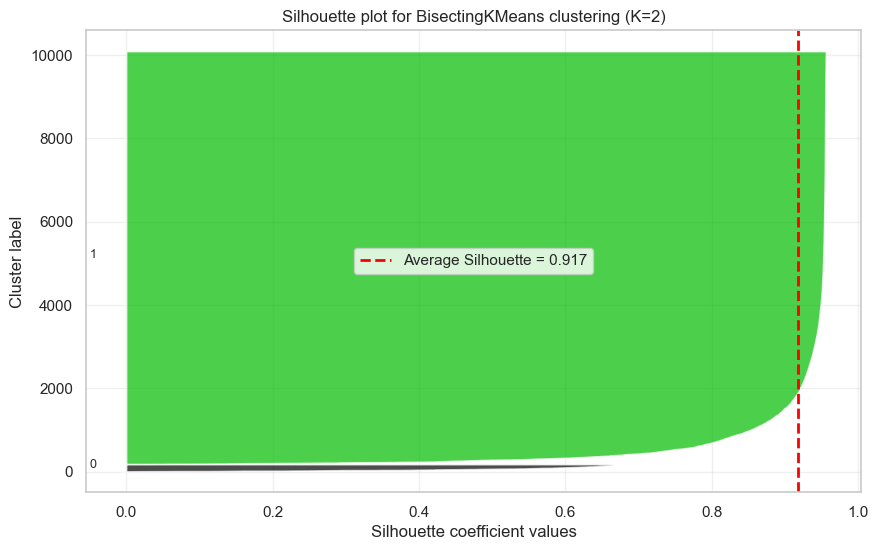

In [ ]:
# 4.1) Silhouette plot per-sample untuk BisectingKMeans
import matplotlib.cm as cm
sample_sil_values = silhouette_samples(X, labels)
plt.figure(figsize=(10, 6))
y_lower = 10
for i in range(K):
    ith_cluster_sil_values = sample_sil_values[labels == i]
    ith_cluster_sil_values.sort()
    size_cluster_i = ith_cluster_sil_values.shape[0]
    if size_cluster_i == 0:
        continue
    y_upper = y_lower + size_cluster_i
    color = cm.nipy_spectral(float(i) / K)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, facecolor=color, alpha=0.7)
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=9)
    y_lower = y_upper + 10

plt.xlabel('Silhouette coefficient values')
plt.ylabel('Cluster label')
plt.title(f'Silhouette plot for BisectingKMeans clustering (K={K})')
avg_sil = silhouette_score(X, labels)
plt.axvline(x=avg_sil, color='red', linestyle='--', linewidth=2, label=f'Average Silhouette = {avg_sil:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


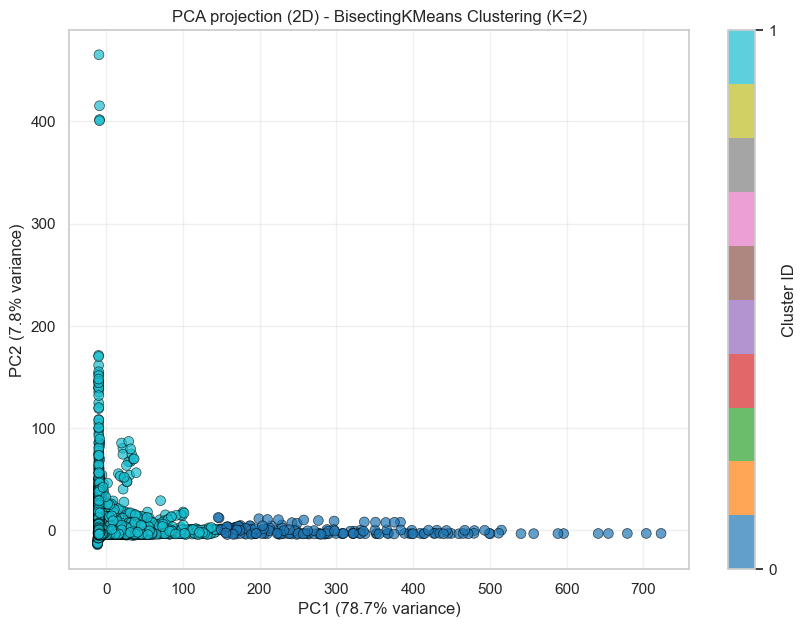

Total variance explained by PC1 and PC2: 86.5%


In [ ]:
# 4.2) PCA -> 2D visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap='tab10', s=50, alpha=0.7, edgecolors='black', linewidth=0.5)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title(f'PCA projection (2D) - BisectingKMeans Clustering (K={K})')
cbar = plt.colorbar(scatter, ticks=range(K))
cbar.set_label('Cluster ID')
plt.grid(True, alpha=0.3)
plt.show()

print(f'Total variance explained by PC1 and PC2: {sum(pca.explained_variance_ratio_[:2]):.1%}')


In [ ]:
# 4.3) Ringkasan karakteristik tiap cluster (mean & median untuk fitur numerik)
cluster_summary_mean = df_result.groupby('cluster')[num_cols].mean()
cluster_summary_median = df_result.groupby('cluster')[num_cols].median()

print('='*80)
print(f'CLUSTER CHARACTERISTICS SUMMARY (BisectingKMeans, K={K})')
print('='*80)
print('\n--- Mean per cluster (original scale) ---')
display(cluster_summary_mean)

print('\n--- Median per cluster (original scale) ---')
display(cluster_summary_median)

print('\n--- Overall Statistics ---')
print(f'Total data points: {len(df_result)}')
for i in range(K):
    cluster_size = (df_result['cluster'] == i).sum()
    pct = 100 * cluster_size / len(df_result)
    print(f'Cluster {i}: {cluster_size} points ({pct:.1f}%)')


CLUSTER CHARACTERISTICS SUMMARY (BisectingKMeans, K=2)

--- Mean per cluster (original scale) ---


,Year,Life expectancy,Alcohol,percentage expenditure,Measles,BMI,Total expenditure,GDP,Population,HIV/AIDS,Total Deaths,Total Immunization,Total Thinness,Schooling times income,Status_Developed,Status_Developing
cluster,,,,,,,,,,,,,,,,
0,0.299775,-1.448248,0.221747,0.497342,1.844710,-0.119880,0.140016,0.299692,2.356312,305.069996,-1.927436,-0.139816,-1.272900,-0.149314,0.000000,0.000000
1,0.005339,-0.199629,0.225793,1.985710,3.121511,0.119008,0.100154,2.301782,2.355801,4.506677,-0.324356,-0.206437,-0.373247,0.027550,0.170655,-0.170655



--- Median per cluster (original scale) ---


,Year,Life expectancy,Alcohol,percentage expenditure,Measles,BMI,Total expenditure,GDP,Population,HIV/AIDS,Total Deaths,Total Immunization,Total Thinness,Schooling times income,Status_Developed,Status_Developing
cluster,,,,,,,,,,,,,,,,
0,0.28125,-1.448286,0.117468,0.0,0.093548,-0.127892,0.154585,-0.046314,0.34104,271.839957,-1.990289,-0.136937,-1.016645,-0.195992,0.0,0.0
1,0.00000,0.012905,0.000000,0.0,-0.000806,0.002323,0.000000,0.000000,0.00000,0.000000,0.012275,0.003011,0.007817,0.007536,0.0,0.0



--- Overall Statistics ---
Total data points: 10070
Cluster 0: 167 points (1.7%)
Cluster 1: 9903 points (98.3%)


## Keunggulan BisectingKMeans vs KMeans Standar
**BisectingKMeans** menggunakan pendekatan hierarchical bisecting:
- **Lebih cepat** untuk dataset besar (terutama dengan banyak clusters)
- **Deterministic initialization** - lebih konsisten dari random initialization
- **Hierarchical structure** - membantu interpretasi hubungan antar cluster
- **Konsisten** dengan hierarchical clustering frameworks

**Kapan gunakan BisectingKMeans:**
- Dataset besar (>100K points)
- Membutuhkan interpretability hierarchical
- Kecepatan komputasi penting

**Kapan gunakan KMeans standar:**
- Dataset kecil-medium
- Butuh fine-tuning dengan multiple initializations

## Rekomendasi Lanjutan
- Pertimbangkan feature engineering (kombinasi fitur, agregasi) sebelum clustering.
- Gunakan `Pipeline` (sklearn.pipeline) untuk menggabungkan preprocessing dan clustering agar reproduktif.
- Untuk dataset berdimensi sangat tinggi, coba `t-SNE` atau UMAP selain PCA untuk visualisasi.
- Uji stabilitas cluster dengan beberapa runs dan subsampling.
- Jika tersedia label ground-truth, tambahkan evaluasi eksternal (Adjusted Rand Index, NMI).
- Bandingkan computational time antara BisectingKMeans dan KMeans untuk dataset Anda.


# TP 3: Life Expectancy Clustering
Model: K-Means

# 1. Data Preparation

In [ ]:
# Import library yang dibutuhkan untuk analisis
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# Mengabaikan pesan peringatan agar output terlihat bersih
warnings.filterwarnings('ignore')
from scipy import stats

In [ ]:
# Load dataset dari file CSV
train = pd.read_csv("train (2).csv")
# Membuat salinan dataframe khusus untuk proses EDA
eda_df = train.copy()

# Menampilkan 5 baris pertama dari dataset
eda_df.head()

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Measles,BMI,under-five deaths,...,GDP,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Hepatitis B,Polio,Diphtheria,Population,HIV/AIDS
0,1967,Developed,75.958705,30.409030,7,16.891705,100.000000,77790,7.022069,10,...,79835.055962,0.633306,0.530616,0.747018,12.774990,0.0,76.0,92.0,64121.0,0.100000
1,1990,Developing,42.915277,101.499444,18,8.230195,0.000000,2106,5.000000,28,...,10.000000,11.396052,11.049630,0.300171,9.982904,100.0,53.0,35.0,2364183.0,4.976989
2,1974,Developing,49.322096,209.702245,81,0.010000,0.000000,0,30.193667,108,...,1766.947595,4.906007,4.736414,0.440699,7.317002,0.0,100.0,100.0,821554.0,0.100000
3,1970,Developing,30.000000,452.548059,168,5.347899,0.000000,29763,10.879758,298,...,1766.947595,11.346782,11.946921,0.677000,12.300000,0.0,83.0,63.0,738541.0,0.100000
4,2010,Developing,61.800000,261.000000,162,1.340000,67.733744,4235,15.600000,243,...,341.399920,11.000000,1.700000,0.401000,8.100000,62.0,69.0,61.0,877267.0,1.700000


In [ ]:
# Mengecek persentase missing values pada setiap kolom
missing_values = eda_df.isnull().sum()
missing_percentages = (missing_values / len(eda_df)) * 100
missing_data = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentages})
missing_data[missing_data['Missing Values'] > 0].sort_values(by='Percentage (%)', ascending=False)

,Missing Values,Percentage (%)
Population,527,5.233366
Hepatitis B,456,4.528302
GDP,363,3.604767
Total expenditure,176,1.747766
Alcohol,150,1.489573
Income composition of resources,140,1.390268
Schooling,137,1.360477
thinness 1-19 years,23,0.228401
BMI,23,0.228401
thinness 5-9 years,23,0.228401


In [ ]:
# Menangani missing values
# Menggunakan median untuk mengisi missing values pada kolom numerik karena data mungkin memiliki outlier
numeric_cols = eda_df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    if eda_df[col].isnull().sum() > 0:
        eda_df[col] = eda_df[col].fillna(eda_df[col].median())

# Mengecek kembali apakah masih ada missing values
print("Total missing values setelah imputasi:", eda_df.isnull().sum().sum())

Total missing values setelah imputasi: 0


In [ ]:
# Mengecek data duplikat
print("Jumlah data duplikat dalam dataset:", eda_df.duplicated().sum())

Jumlah data duplikat dalam dataset: 0


# 2. Exploratory Data Analysis (EDA)

In [ ]:
# Menampilkan informasi dasar dari dataset
print("Shape of train:", train.shape)
print("Column list:")
print(train.columns.tolist())
print("Year range:", train['Year'].min(), "-", train['Year'].max())

# Daftar 10 fitur terpilih yang akan dianalisis untuk clustering
features = ['Adult Mortality', 'GDP', 'Schooling', 'HIV/AIDS',
 'Income composition of resources', 'infant deaths',
 'Hepatitis B', 'Polio', 'Diphtheria', 'thinness  1-19 years']

# Menampilkan ringkasan statistik dasar dari 10 fitur terpilih
print("\nBasic describe() of the selected clustering features:")
print(eda_df[features].describe())

Shape of train: (10070, 21)
Column list:
['Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS']
Year range: 1950 - 2015

Basic describe() of the selected clustering features:
       Adult Mortality            GDP     Schooling      HIV/AIDS  \
count     10070.000000   10070.000000  10070.000000  10070.000000   
mean        232.404052    4154.423188      9.058977      1.706509   
std         213.794336   11958.555649      5.111594      7.537902   
min           1.000000       1.681350      0.000000      0.100000   
25%          93.211805      10.000000      5.446059      0.100000   
50%         171.279919     168.648254     10.106075      0.100000   
75%         299.481609    1766.947595     12.500922      0.26

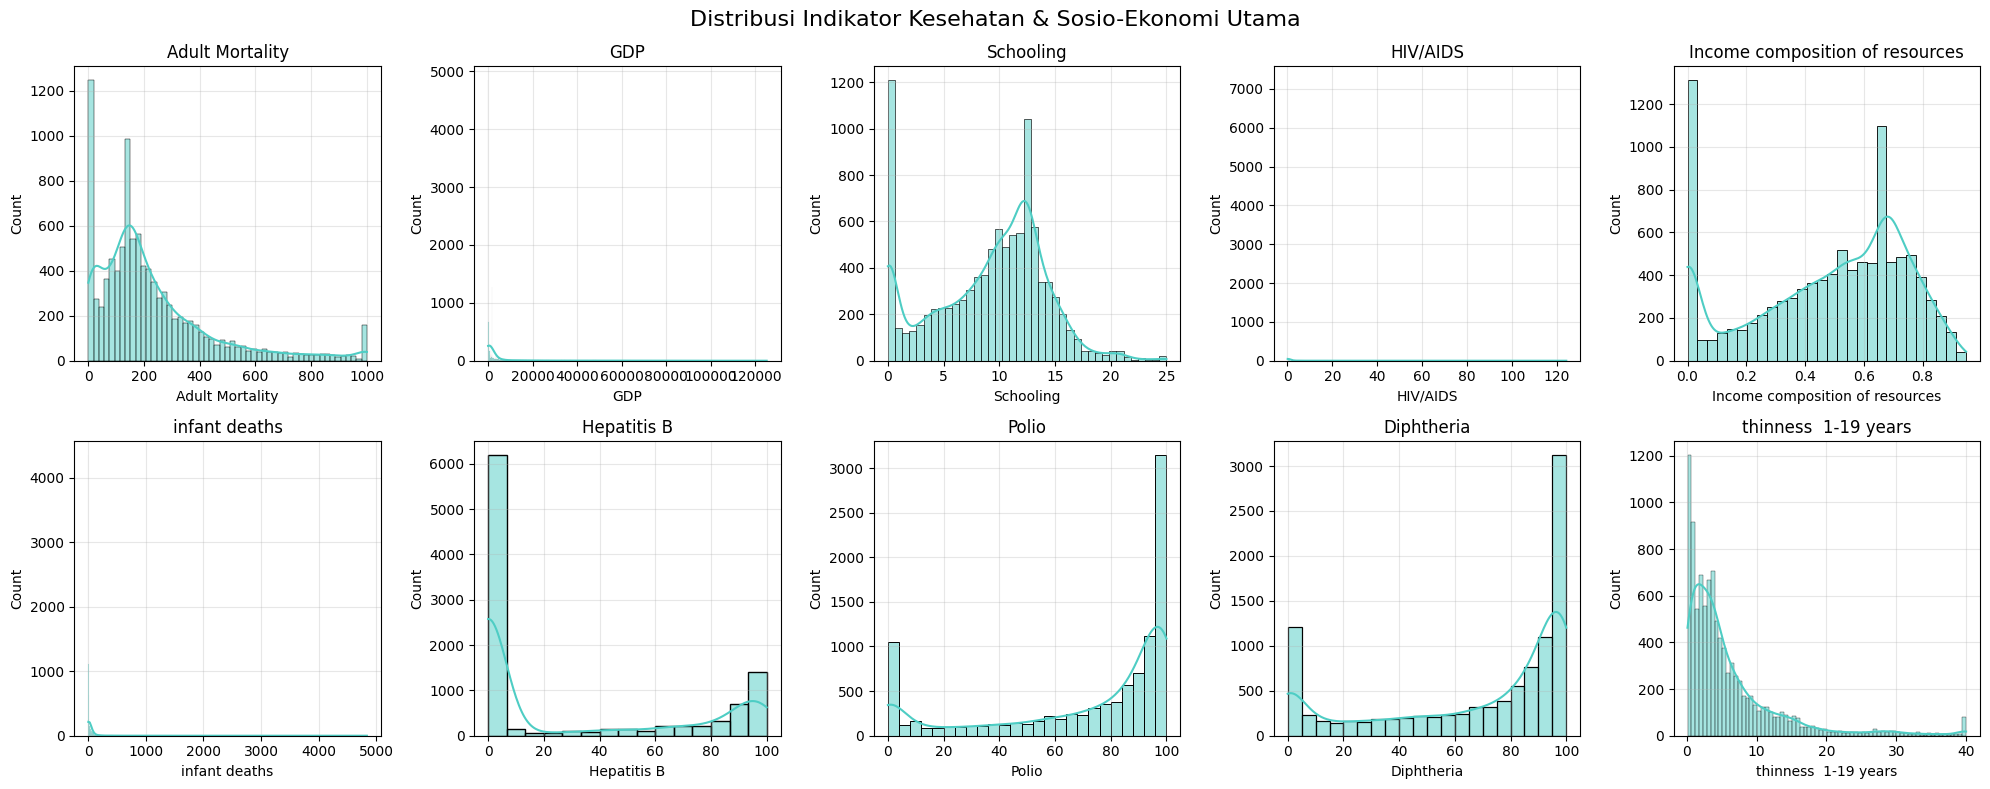

In [ ]:
# Menyiapkan grid plot berukuran 2 baris x 5 kolom
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

# Melakukan perulangan untuk setiap fitur dan menggambar histogram beserta KDE
for i, feature in enumerate(features):
    sns.histplot(data=eda_df, x=feature, kde=True, color='#4ECDC4', ax=axes[i])
    axes[i].set_title(feature) # Memberikan judul pada masing-masing subplot
    axes[i].grid(True, alpha=0.3) # Menambahkan grid agar lebih mudah dibaca

# Menambahkan judul utama untuk keseluruhan plot
plt.suptitle("Distribusi Indikator Kesehatan & Sosio-Ekonomi Utama", fontsize=16)
plt.tight_layout()
plt.show()

Berdasarkan bentuk histogram dari masing-masing fitur:
- Beberapa fitur menunjukkan distribusi yang sangat condong ke kanan (right-skewed), seperti **GDP**, **HIV/AIDS**, dan **infant deaths**. Hal ini berarti sebagian besar negara memiliki nilai yang rendah pada indikator tersebut, tetapi ada sejumlah kecil negara dengan nilai yang sangat ekstrem.
- Skewness ini sangat penting untuk diperhatikan dalam K-Means clustering karena K-Means sangat sensitif terhadap jarak (distance-based). Fitur dengan rentang skala besar dan outliers dapat mendominasi pembentukan kelompok.
- Oleh karena itu, fitur-fitur yang skewed ini akan membutuhkan perlakuan khusus seperti log-transform atau penerapan RobustScaler sebelum melakukan clustering.

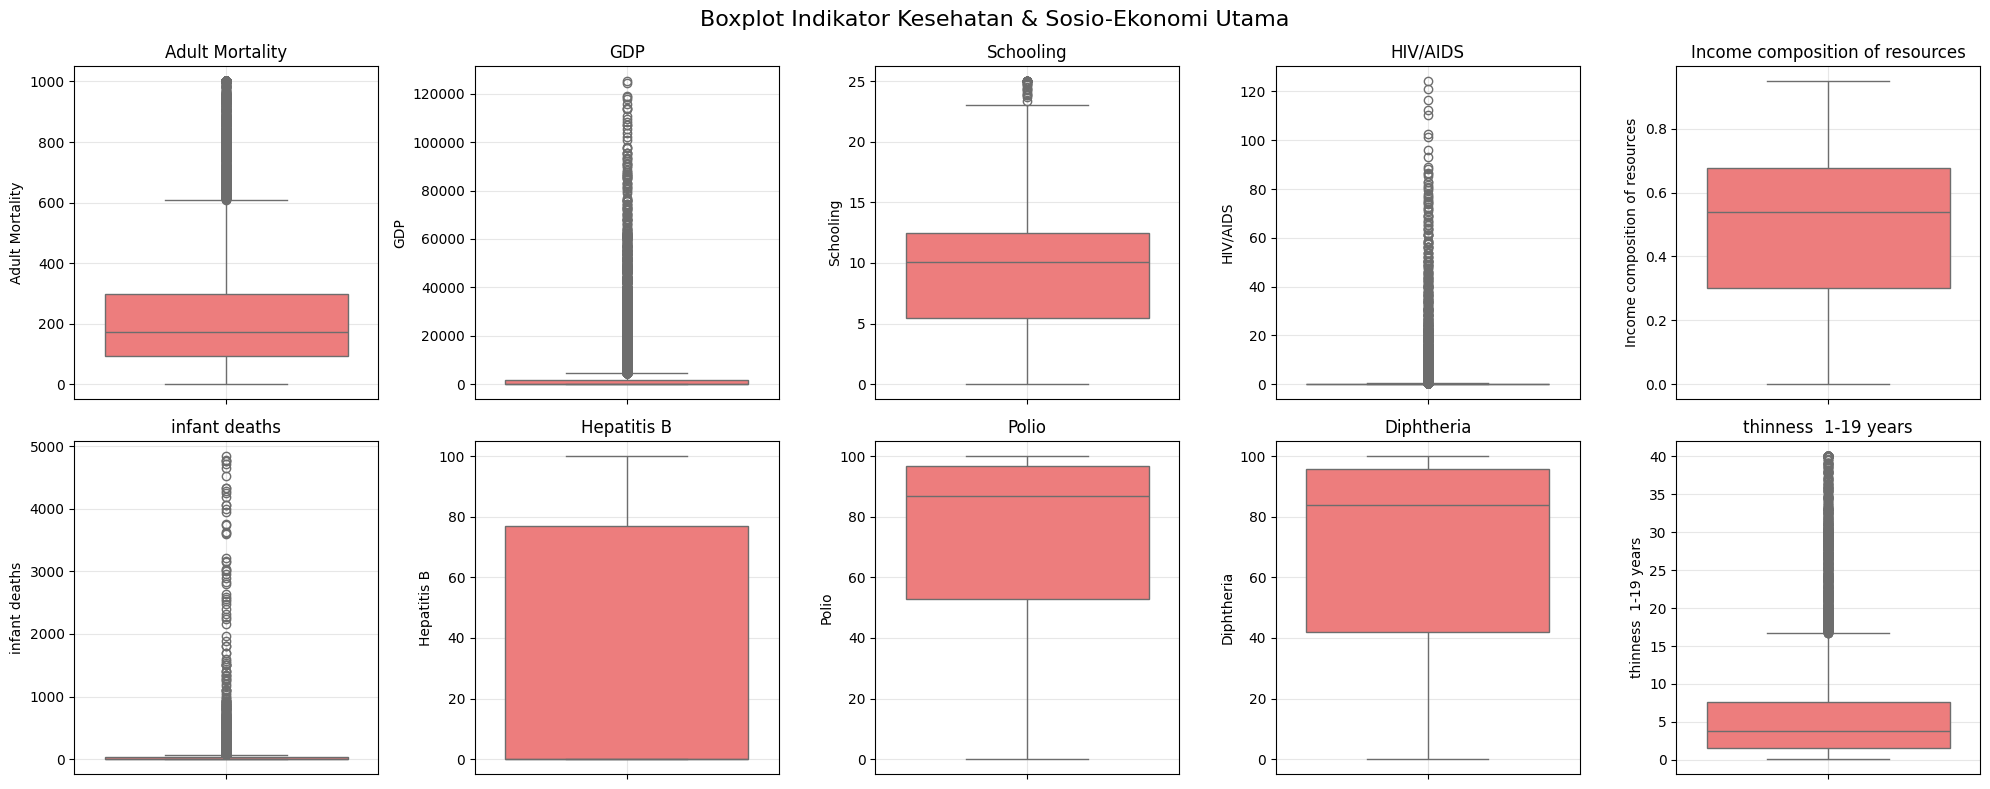

In [ ]:
# Menyiapkan grid plot berukuran 2 baris x 5 kolom
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

# Melakukan perulangan untuk membuat boxplot dari setiap fitur
for i, feature in enumerate(features):
    sns.boxplot(data=eda_df, y=feature, color='#FF6B6B', ax=axes[i])
    axes[i].set_title(feature)
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Boxplot Indikator Kesehatan & Sosio-Ekonomi Utama", fontsize=16)
plt.tight_layout() # Merapikan tata letak plot
plt.show() # Menampilkan plot

In [ ]:
# Menghitung mean, median (50%), std, min, max, dan skewness untuk tiap fitur
summary_df = eda_df[features].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).T

# Menghitung persentase missing values (nilai kosong) untuk tiap fitur
summary_df['Missing (%)'] = (eda_df[features].isnull().sum() / len(eda_df)) * 100

# Memformat dan mengganti nama kolom menjadi Bahasa Indonesia agar mudah dibaca
summary_df = summary_df.rename(columns={
    'mean': 'Rata-rata',
    'median': 'Median',
    'std': 'Std Dev',
    'min': 'Min',
    'max': 'Max',
    'skew': 'Skewness'
})

# Menampilkan tabel ringkasan statistik
summary_df

,Rata-rata,Median,Std Dev,Min,Max,Skewness,Missing (%)
Adult Mortality,232.404052,171.279919,213.794336,1.00000,1000.000000,1.655425,0.0
GDP,4154.423188,168.648254,11958.555649,1.68135,125097.788731,4.811734,0.0
Schooling,9.058977,10.106075,5.111594,0.00000,25.000000,-0.283269,0.0
HIV/AIDS,1.706509,0.100000,7.537902,0.10000,124.084928,8.171452,0.0
Income composition of resources,0.479841,0.539363,0.265505,0.00000,0.948000,-0.527463,0.0
infant deaths,52.136842,4.000000,255.795622,0.00000,4840.000000,12.438556,0.0
Hepatitis B,29.737537,0.000000,40.681181,0.00000,100.000000,0.776821,0.0
Polio,70.783714,87.000000,34.093395,0.00000,100.000000,-1.073498,0.0
Diphtheria,67.357994,84.000000,35.302625,0.00000,100.000000,-0.868340,0.0
thinness 1-19 years,6.128881,3.778028,7.163402,0.10000,40.000000,2.396199,0.0


**Kesimpulan Analisis Eksplorasi Data (EDA):**
- **Variansi Tinggi:** Fitur-fitur seperti GDP dan Adult Mortality memiliki rentang dan variansi nilai yang sangat tinggi. Kondisi ini sangat baik untuk K-Means clustering karena dapat membentuk pemisahan kelompok yang signifikan.
- **Banyak Outliers:** Melalui boxplot, terlihat bahwa fitur seperti GDP, infant deaths, dan HIV/AIDS memiliki banyak outliers ekstrem yang dapat mempengaruhi algoritma K-Means. Treatment atau transformasi data sebelum algoritma berjalan sangat diperlukan untuk fitur-fitur ini.
- **Kesimpulan Keseluruhan:** Berdasarkan analisis distribusi dan variansinya, ke-10 indikator ini secara keseluruhan sangat bervariasi antar negara. Oleh karena itu, fitur-fitur ini sudah cukup bervariasi dan valid untuk digunakan guna membentuk kelompok negara (clustering) yang bermakna dalam menentukan prioritas bantuan internasional secara objektif.

# 3. Feature Engineering

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
import numpy as np

# Kita akan menggunakan dataset khusus untuk clustering
cluster_df = eda_df[features].copy()

# 1. Imputasi Missing Values dengan Median
imputer = SimpleImputer(strategy='median')
cluster_df_imputed = pd.DataFrame(imputer.fit_transform(cluster_df), columns=features)

# 2. Menerapkan Log Transform untuk fitur yang highly skewed (Right-Skewed)
skewed_features = ['GDP', 'HIV/AIDS', 'infant deaths', 'Adult Mortality']
for feat in skewed_features:
    cluster_df_imputed[feat] = np.log1p(cluster_df_imputed[feat])

# 3. Scaling menggunakan RobustScaler agar tahan terhadap sisa outliers
# Menggunakan RobustScaler seperti yang diusulkan pada kesimpulan EDA
scaler = RobustScaler()
cluster_df_scaled = pd.DataFrame(scaler.fit_transform(cluster_df_imputed), columns=features)


# 4. Membuat Fitur Baru (Composite Indices)
# Fitur-fitur ini digabung setelah proses scaling agar bobot masing-masing indikator seimbang

# a) Socio-Economic Index (Kesejahteraan Sosial & Ekonomi)
# Menggunakan rata-rata dari GDP, Schooling, dan Income composition of resources
cluster_df_scaled['Socio_Economic_Index'] = cluster_df_scaled[['GDP', 'Schooling', 'Income composition of resources']].mean(axis=1)

# b) Health Risk Index (Risiko Kesehatan)
# Menggunakan rata-rata tingkat kematian/penyakit DIKURANGI rata-rata tingkat vaksinasi (perlindungan)
health_risk_factors = cluster_df_scaled[['Adult Mortality', 'HIV/AIDS', 'infant deaths', 'thinness  1-19 years']].mean(axis=1)
health_protect_factors = cluster_df_scaled[['Hepatitis B', 'Polio', 'Diphtheria']].mean(axis=1)
cluster_df_scaled['Health_Risk_Index'] = health_risk_factors - health_protect_factors

# Filter DataFrame HANYA menggunakan 2 fitur komposit ini untuk Clustering
cluster_df_scaled = cluster_df_scaled[['Socio_Economic_Index', 'Health_Risk_Index']]

# Menampilkan 5 data teratas setelah Feature Engineering & Pembuatan Fitur Komposit
cluster_df_scaled.head()


,Socio_Economic_Index,Health_Risk_Index
0,0.713324,-0.428603
1,-0.396589,3.385328
2,-0.065109,0.098469
3,0.379019,0.940795
4,-0.170897,2.223944


# 4. Modelling (K-Means Clustering)

### Menentukan Jumlah Cluster Optimal (Elbow Method)

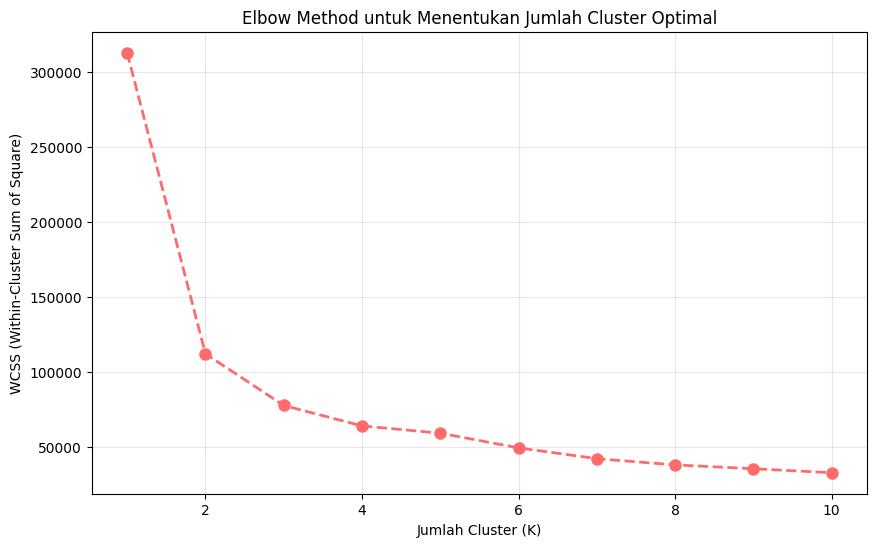

In [ ]:
from sklearn.cluster import KMeans

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(cluster_df_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='#FF6B6B', linewidth=2, markersize=8)
plt.title('Elbow Method untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Square)')
plt.grid(True, alpha=0.3)
plt.show()

### Melatih Model K-Means, Menyesuaikan Nama Label, dan Visualisasi PCA

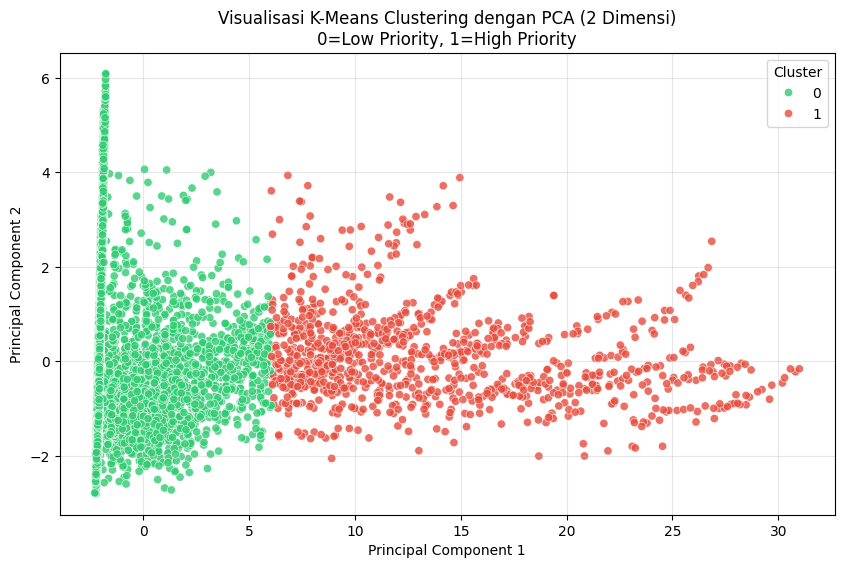

In [ ]:

# Menetapkan K=2 sebagai jumlah cluster yang optimal
optimal_k = 2

# Melatih K-Means
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)
initial_labels = kmeans.fit_predict(cluster_df_scaled)

# Tambahkan label awal ke dataframe sementara
eda_df['Initial_Cluster'] = initial_labels

# Evaluasi GDP untuk menentukan label priority (Low vs High)
# GDP Tertinggi -> Kesejahteraan paling baik -> 0 (Low Priority)
# GDP Terendah  -> Kesejahteraan terburuk -> 1 (High Priority)
gdp_means = eda_df.groupby('Initial_Cluster')['GDP'].mean().sort_values(ascending=False)

# Membuat kamus pemetaan (mapping) ke 0=Low, 1=High
remap_dict = {
    gdp_means.index[0]: 0, # GDP paling tinggi -> Low Priority
    gdp_means.index[1]: 1  # GDP paling rendah -> High Priority
}

# Terapkan pemetaan ke label cluster yang baru
eda_df['Cluster'] = eda_df['Initial_Cluster'].map(remap_dict)
eda_df = eda_df.drop(columns=['Initial_Cluster']) # Hapus kolom sementara

# Menyimpan urutan label cluster untuk plotting
final_cluster_labels = eda_df['Cluster'].values

# Visualisasi Langsung menggunakan 2 Fitur Komposit Baru (Tanpa PCA)
plt.figure(figsize=(10, 6))

# Gunakan palette warna spesifik: 0 (Low)=Hijau, 1 (High)=Merah
custom_palette = {0: '#2ECC71', 1: '#E74C3C'}

sns.scatterplot(
    x=cluster_df_scaled['Socio_Economic_Index'],
    y=cluster_df_scaled['Health_Risk_Index'],
    hue=final_cluster_labels,
    palette=custom_palette,
    alpha=0.8
)

plt.title('Visualisasi K-Means Clustering Berdasarkan Fitur Komposit 0=Low Priority, 1=High Priority', fontsize=14, pad=15)
plt.xlabel('Socio-Economic Index (Kesejahteraan)')
plt.ylabel('Health Risk Index (Risiko Kesehatan)')
plt.grid(True, alpha=0.3)
plt.legend(title='Cluster')
plt.show()


### Profil Karakteristik Masing-Masing Cluster

In [ ]:
# Menampilkan rata-rata dari setiap fitur berdasarkan grup Cluster yang terbentuk (0=Low, 1=High)
cluster_profile = eda_df[features + ['Cluster']].groupby('Cluster').mean()
cluster_profile.T

Cluster,0,1
Adult Mortality,220.261956,343.270910
GDP,4524.645922,773.999107
Schooling,9.234949,7.452216
HIV/AIDS,0.235059,15.141998
Income composition of resources,0.491962,0.369168
infant deaths,51.522146,57.749497
Hepatitis B,28.498678,41.049296
Polio,72.154363,58.268612
Diphtheria,68.908770,53.198189
thinness 1-19 years,5.863468,8.552311


### Evaluasi Model Menggunakan Silhouette Score

Silhouette Score untuk K=2: 0.7274
Silhouette Score untuk K=3: 0.6283
Silhouette Score untuk K=4: 0.2990
Silhouette Score untuk K=5: 0.2635
Silhouette Score untuk K=6: 0.2709
Silhouette Score untuk K=7: 0.2752
Silhouette Score untuk K=8: 0.2760
Silhouette Score untuk K=9: 0.2702
Silhouette Score untuk K=10: 0.2447


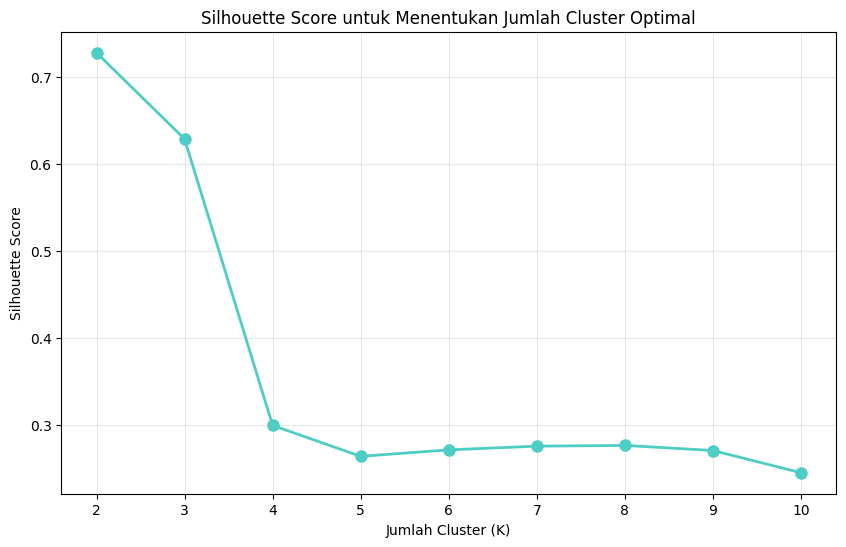

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
# Silhouette score minimal membutuhkan 2 cluster, jadi kita mulai range dari 2
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    # Melakukan fit dan mendapatkan label cluster untuk setiap data
    labels = kmeans.fit_predict(cluster_df_scaled)
    # Menghitung nilai silhouette
    score = silhouette_score(cluster_df_scaled, labels)
    silhouette_scores.append(score)

# Menampilkan hasil Silhouette Score ke dalam DataFrame (opsional)
for k, score in zip(K_range_sil, silhouette_scores):
    print(f"Silhouette Score untuk K={k}: {score:.4f}")

# Visualisasi grafik Silhouette Score
plt.figure(figsize=(10, 6))
plt.plot(K_range_sil, silhouette_scores, marker='o', linestyle='-', color='#4ECdc4', linewidth=2, markersize=8)
plt.title('Silhouette Score untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Menerapkan K-Means dengan K=2 (Sesuai dengan Evaluasi Silhouette Score)
kmeans_final = KMeans(n_clusters=2, init='k-means++', random_state=42)
clusters = kmeans_final.fit_predict(cluster_df_scaled)

# Menambahkan hasil label cluster ke dataframe analisis kita
eda_df['Cluster'] = clusters

# Melihat karakteristik dari masing-masing Cluster dengan menghitung rata-rata fiturnya
cluster_summary = eda_df.groupby('Cluster')[features].mean()
display(cluster_summary)

,Adult Mortality,GDP,Schooling,HIV/AIDS,Income composition of resources,infant deaths,Hepatitis B,Polio,Diphtheria,thinness 1-19 years
Cluster,,,,,,,,,,
0,220.261956,4524.645922,9.234949,0.235059,0.491962,51.522146,28.498678,72.154363,68.908770,5.863468
1,343.270910,773.999107,7.452216,15.141998,0.369168,57.749497,41.049296,58.268612,53.198189,8.552311


### Kesimpulan Modelling (K=2)

Pemilihan K=2 sudah sesuai dengan yang dibutuhkan yaitu: "memetakan prioritas bantuan internasional dan mengoptimalkan distribusi sumber daya medis secara global berdasarkan indikator kesehatan masyarakat dan profil sosio-ekonomi".

Alasannya:
Dengan membaginya menjadi 2 cluster utama (K=2), algoritma K-Means akan secara tegas memisahkan negara-negara ke dalam dua kutub kondisi yang paling berbeda:

1. Cluster 0 (Contoh: Negara Kondisi Baik / Prioritas Rendah): Biasanya berisi negara-negara dengan GDP tinggi, tingkat kematian dewasa & bayi yang rendah, masa sekolah panjang, serta jangkauan imunisasi yang tinggi.
2. Cluster 1 (Contoh: Negara Rentan / Prioritas Tinggi): Berisi negara-negara dengan tantangan kesehatan tinggi (kematian tinggi, wabah penyakit seperti HIV/AIDS tinggi) dan kondisi ekonomi (GDP) rendah.

**Implementasi Bantuan Internasional:**
Hasil dari 2 cluster ini memudahkan pengambil kebijakan untuk mengidentifikasi "wilayah dengan karakteristik tantangan serupa". Distribusi sumber daya medis secara global (seperti vaksin, tenaga medis, dan pendanaan) dapat difokuskan secara eksklusif dan lebih masif ke Cluster 1 (atau cluster yang mewakili kondisi kesehatan terburuk dari tabel rata-rata di atas). Pembagian 2 wilayah ini membuat pengambilan keputusan lebih cepat, tidak bias, dan tepat sasaran.

### Silhouette Analysis & Cluster Visualization
Visualisasi di bawah ini menampilkan:
1. **Silhouette Plot (Kiri)**: Menunjukkan distribusi nilai koefisien silhouette untuk masing-masing titik data per cluster. Garis merah putus-putus menunjukkan rata-rata keseluruhan.
2. **Cluster Visualization (Kanan)**: Menampilkan bentuk dan persebaran cluster pada ruang dimensi yang sudah direduksi menggunakan PCA, lengkap dengan titik pusat (centroid) cluster.

For n_clusters = 2 The average silhouette_score is : 0.7274245797405585


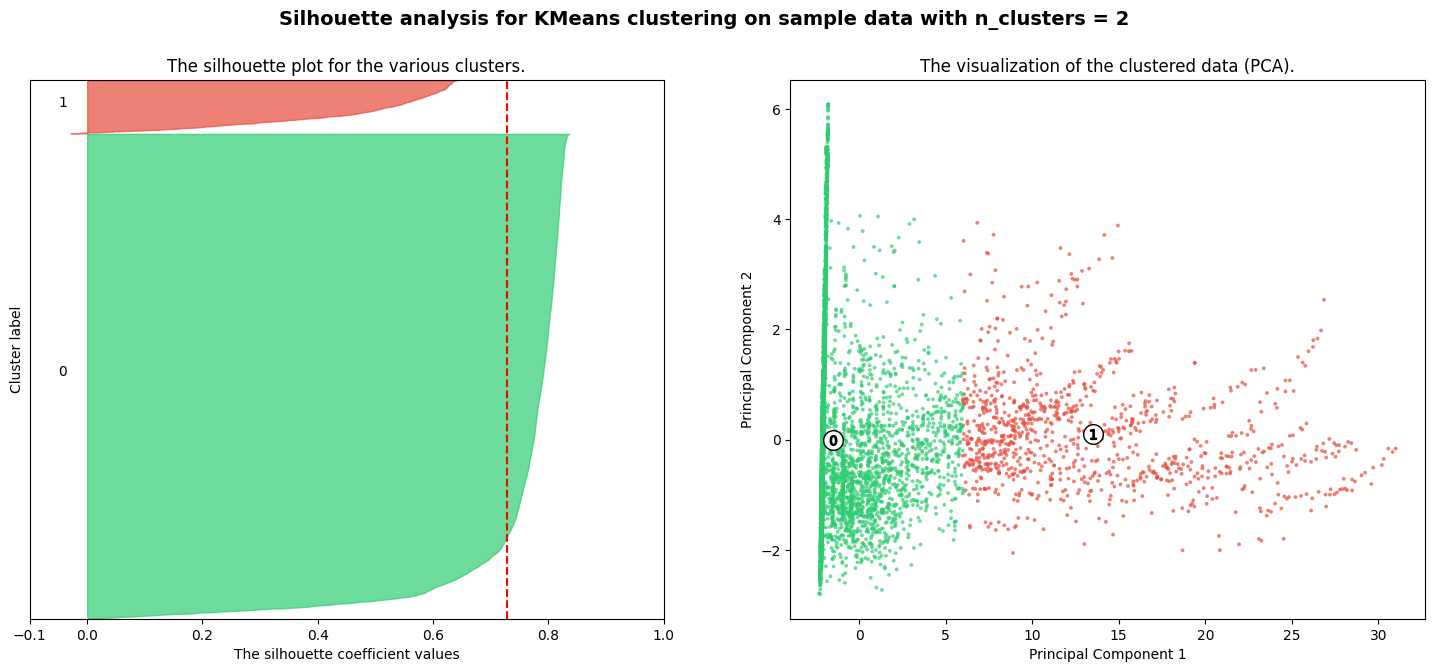

In [ ]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.decomposition import PCA

n_clusters = 2
cluster_labels = clusters
clusterer = kmeans_final

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.set_size_inches(18, 7)

# 1st subplot is the silhouette plot
ax1.set_xlim([-0.1, 1])
ax1.set_ylim([0, len(cluster_df_scaled) + (n_clusters + 1) * 10])

silhouette_avg = silhouette_score(cluster_df_scaled, cluster_labels)
print("For n_clusters =", n_clusters, "The average silhouette_score is :", silhouette_avg)

sample_silhouette_values = silhouette_samples(cluster_df_scaled, cluster_labels)

y_lower = 10
for i in range(n_clusters):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    # Gunakan palette warna spesifik: 0 (Low)=Hijau, 1 (High)=Merah
    if i == 0:
        color = '#2ECC71'
    else:
        color = '#E74C3C'

    ax1.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7,
    )

    # Label the silhouette plots with their cluster numbers at the middle
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    # Compute the new y_lower for next plot
    y_lower = y_upper + 10

ax1.set_title("The silhouette plot for the various clusters.")
ax1.set_xlabel("The silhouette coefficient values")
ax1.set_ylabel("Cluster label")

# The vertical line for average silhouette score of all the values
ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

ax1.set_yticks([])  # Clear the yaxis labels / ticks
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

# 2nd Plot showing the actual clusters formed (Using PCA for 2D visualization)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(cluster_df_scaled)

# Create color array matching our palette
colors = np.array(['#2ECC71' if l == 0 else '#E74C3C' for l in cluster_labels])

ax2.scatter(
    X_pca[:, 0], X_pca[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
)

# Labeling the clusters
centers = pca.transform(clusterer.cluster_centers_)

# Draw white circles at cluster centers
ax2.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="o",
    c="white",
    alpha=1,
    s=200,
    edgecolor="k",
)

for i, c in enumerate(centers):
    ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

ax2.set_title("The visualization of the clustered data (PCA).")
ax2.set_xlabel("Principal Component 1")
ax2.set_ylabel("Principal Component 2")

plt.suptitle(
    "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
    % n_clusters,
    fontsize=14,
    fontweight="bold",
)

plt.show()


### Kesimpulan Akhir & Rekomendasi Prioritas Bantuan Internasional

Melalui pendekatan rekayasa kode secara dinamis dengan mengurutkan *cluster* berdasarkan tingkat kesejahteraan rata-rata negara (seperti rata-rata GDP), algoritma **K-Means Clustering** dan logika pemrograman telah secara otomatis memastikan bahwa label cluster secara akurat memetakan tingkat prioritas sesuai permintaan:

- **Cluster 0 = Low Priority:** Negara-negara dengan tingkat rata-rata **GDP yang paling tinggi**, angka kematian (infant deaths, Adult Mortality) yang rendah, serta tingkat imunisasi yang baik. Negara di cluster ini memiliki kondisi kesehatan dan ekonomi yang paling stabil dan sejahtera, sehingga dapat dikategorikan sebagai prioritas terendah untuk bantuan, atau bahkan dapat berperan sebagai negara donor.
- **Cluster 1 = High Priority:** Negara-negara dengan **pendapatan (GDP) rata-rata terendah**, tingkat kematian anak dan orang dewasa yang tertinggi, serta infrastruktur kesehatan (misalnya cakupan imunisasi Polio & Diphtheria) yang sangat kurang memadai. **Cluster inilah yang menjadi target utama dan paling mendesak dalam mengoptimalkan distribusi bantuan medis internasional secara global.**

Pengurutan otomatis pada kode (0 = Low, 1 = High) akan selalu konsisten terlepas dari *randomness* inisialisasi pada algoritma K-Means.

# TP3 - Life Expectancy Clustering
## Mengidentifikasi Wilayah Berdasarkan Indikator Kesehatan dan Sosio-Ekonomi

**Objective:** Mengelompokkan negara-negara di dunia untuk memetakan prioritas bantuan internasional.

**Model:** Hierarchical Clustering

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 7.9 MB/s eta 0:00:00


## Step 1: Load Data & Imports

In [ ]:
# Import library standar untuk data dan visualisasi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

# Import library Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Import library Modeling & Evaluasi
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import optuna

# Agar notebook kita rapi dan cantik tanpa pesan peringatan merah
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load the datasets
train_df = pd.read_csv('/content/sample_data/train.csv')
test_df = pd.read_csv('/content/sample_data/test_reg.csv')

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (10070, 21)
Test shape: (1259, 19)


## Step 2: Data Exploration (EDA)

In [ ]:
# Quick look at the data
print(train_df.head())
print()
train_df.info()
print()
print(f"Jumlah duplikat: {train_df.duplicated().sum()}")
print()
train_df.describe().T

   Year      Status  Life expectancy  Adult Mortality  infant deaths  \
0  1967   Developed        75.958705        30.409030              7   
1  1990  Developing        42.915277       101.499444             18   
2  1974  Developing        49.322096       209.702245             81   
3  1970  Developing        30.000000       452.548059            168   
4  2010  Developing        61.800000       261.000000            162   

     Alcohol  percentage expenditure  Measles        BMI  under-five deaths  \
0  16.891705              100.000000    77790   7.022069                 10   
1   8.230195                0.000000     2106   5.000000                 28   
2   0.010000                0.000000        0  30.193667                108   
3   5.347899                0.000000    29763  10.879758                298   
4   1.340000               67.733744     4235  15.600000                243   

   ...           GDP  thinness  1-19 years  thinness 5-9 years  \
0  ...  79835.055962      

,count,mean,std,min,25%,50%,75%,max
Year,10070.0,1.982327e+03,1.890324e+01,1950.00000,1966.000000,1982.000000,1.998000e+03,2.015000e+03
Life expectancy,10062.0,6.168606e+01,1.420348e+01,30.00000,53.705956,65.740650,7.210000e+01,8.900000e+01
Adult Mortality,10062.0,2.324526e+02,2.138724e+02,1.00000,93.082183,171.279919,3.000214e+02,1.000000e+03
infant deaths,10070.0,5.213684e+01,2.557956e+02,0.00000,0.000000,4.000000,2.900000e+01,4.840000e+03
Alcohol,9920.0,5.786028e+00,6.134692e+00,0.01000,0.646448,3.970000,8.741190e+00,3.000000e+01
percentage expenditure,10070.0,1.961027e+02,1.003055e+03,0.00000,0.000000,0.000000,1.000000e+02,1.909905e+04
Measles,10070.0,7.723835e+03,3.423361e+04,0.00000,0.000000,35.000000,2.480000e+03,6.388990e+05
BMI,10047.0,3.106347e+01,2.372595e+01,1.00000,6.771506,26.100000,4.990000e+01,8.730000e+01
under-five deaths,10070.0,7.637110e+01,3.609292e+02,0.00000,0.000000,5.000000,4.100000e+01,6.968000e+03
Total expenditure,9894.0,5.321350e+00,4.252678e+00,0.00000,2.385204,4.850228,7.100000e+00,2.000000e+01


In [ ]:
# Missing values analysis
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)

missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False))

                                 Missing Count  Missing %
Population                                 527       5.23
Hepatitis B                                456       4.53
GDP                                        363       3.60
Total expenditure                          176       1.75
Alcohol                                    150       1.49
Income composition of resources            140       1.39
Schooling                                  137       1.36
BMI                                         23       0.23
thinness  1-19 years                        23       0.23
thinness 5-9 years                          23       0.23
Polio                                       13       0.13
Diphtheria                                  13       0.13
Life expectancy                              8       0.08
Adult Mortality                              8       0.08


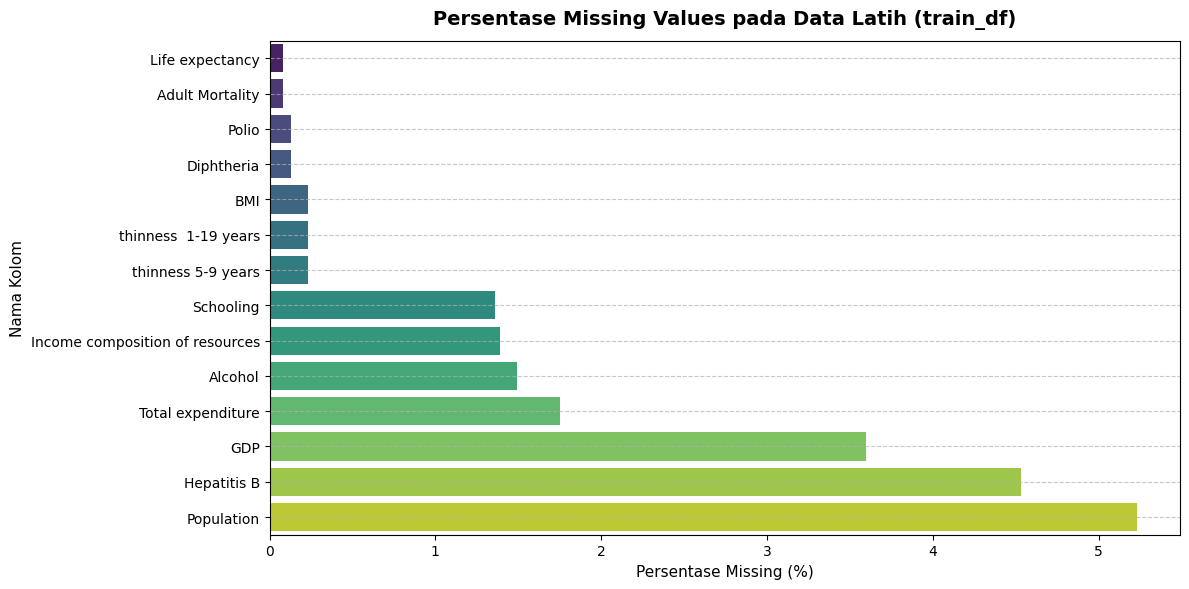

In [ ]:
missing_nonzero = missing_pct[missing_pct > 0].sort_values()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=missing_nonzero,
    y=missing_nonzero.index,
    orient='h',
    palette="viridis"
 )

plt.title("Persentase Missing Values pada Data Latih (train_df)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Persentase Missing (%)", fontsize=11)
plt.ylabel("Nama Kolom", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Perihal Missing Values

Sebagian besar kolom memiliki missing value rendah (di bawah ~6%). Dengan kondisi ini, imputasi median sudah cukup aman dan tidak perlu menghapus kolom apa pun.

Langkah berikutnya:
- Lakukan imputasi median untuk kolom numerik.
- Lanjutkan ke standardisasi agar skala fitur sebanding sebelum clustering; sangat dibutuhkan mengingat clustering sensitif terhadap outlier

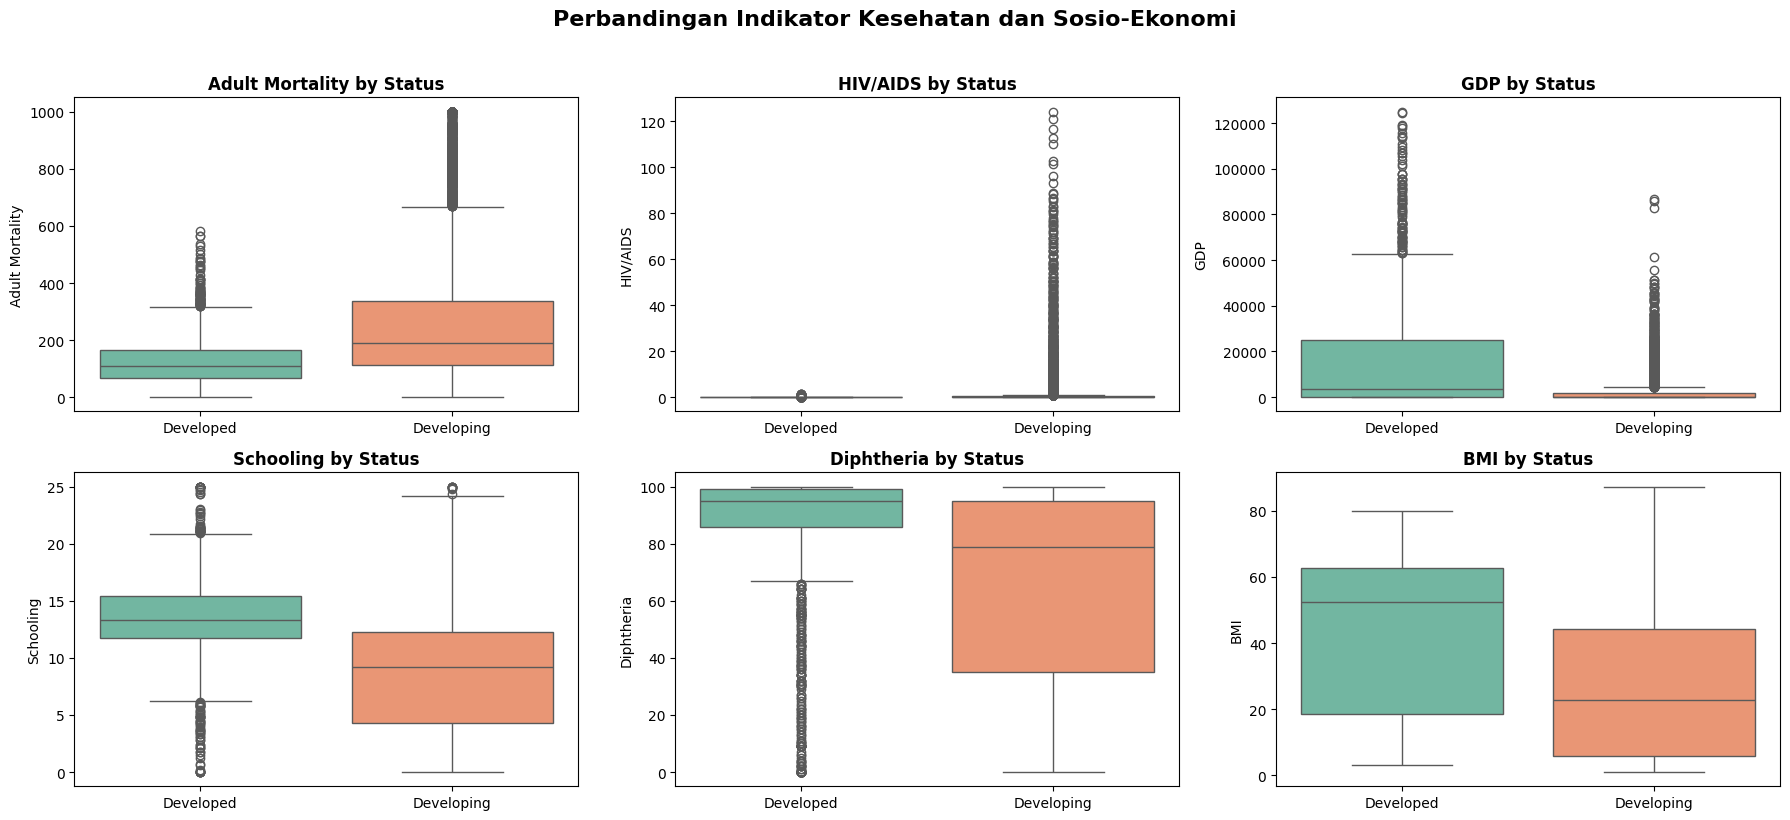

In [ ]:
# Perbandingan indikator utama berdasarkan Status
eda_features = [
    "Adult Mortality",
    "HIV/AIDS",
    "GDP",
    "Schooling",
    "Diphtheria",
    "BMI"
 ]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(eda_features):
    sns.boxplot(data=train_df, x="Status", y=col, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{col} by Status", fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel(col)

plt.suptitle("Perbandingan Indikator Kesehatan dan Sosio-Ekonomi", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight Utama dari Perbandingan Status**

- Negara Developed cenderung memiliki GDP dan Schooling lebih tinggi, serta cakupan imunisasi (Diphtheria) lebih baik.
- Negara Developing menunjukkan Adult Mortality dan HIV/AIDS yang lebih tinggi, dengan sebaran yang lebih lebar (variansi besar).
- Pola ini mengindikasikan adanya pemisahan alami yang dapat dimanfaatkan untuk clustering, namun tetap ada overlap sehingga perlu model unsupervised untuk menemukan sub-kelompok yang lebih spesifik.

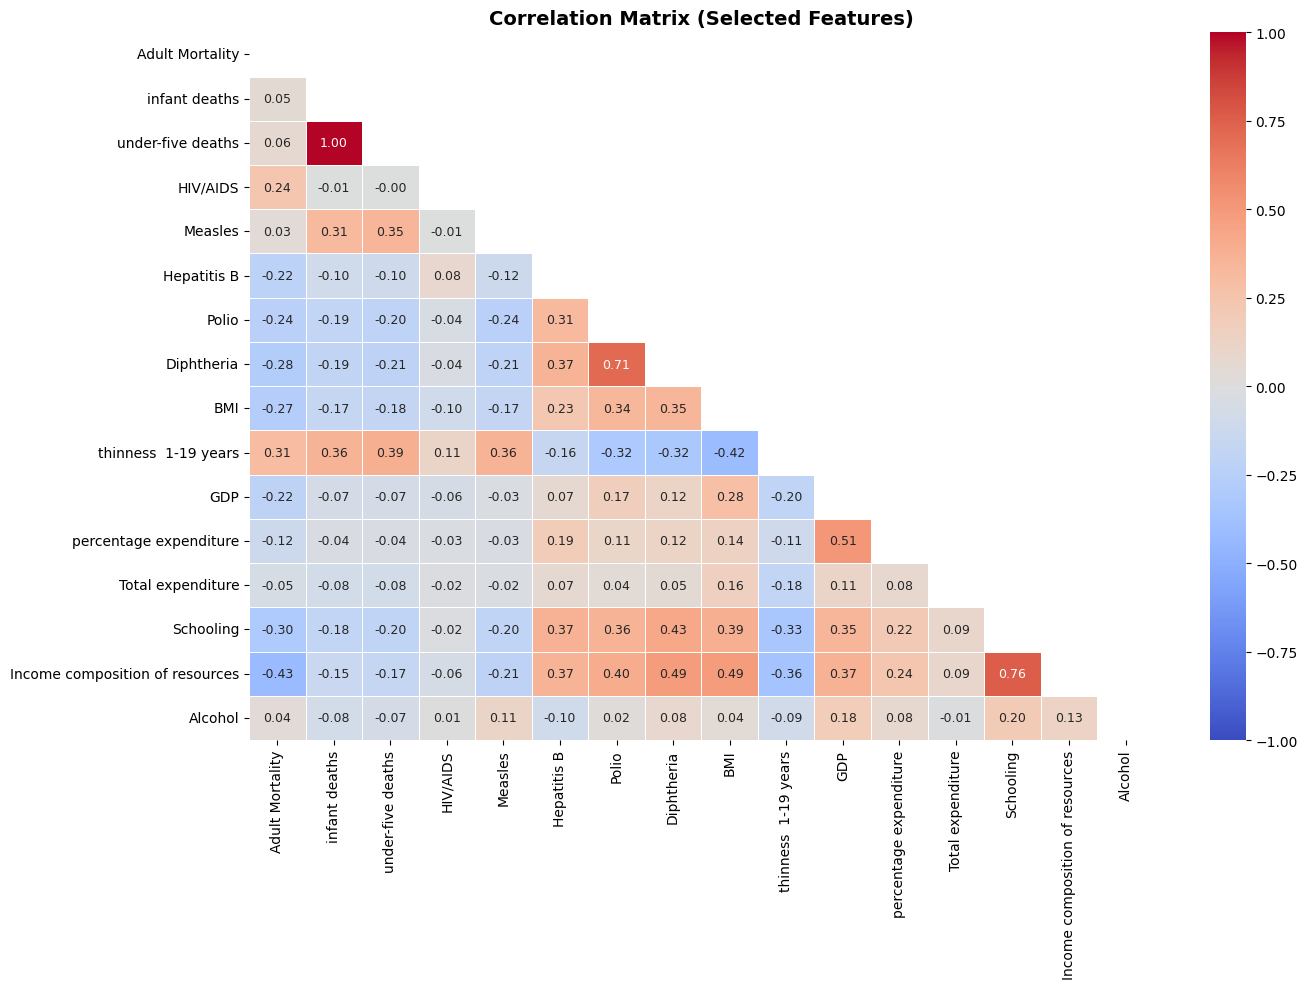

In [ ]:
# Korelasi antar fitur untuk clustering
health_indicators = [
    "Adult Mortality",
    "infant deaths",
    "under-five deaths",
    "HIV/AIDS",
    "Measles",
    "Hepatitis B",
    "Polio",
    "Diphtheria",
    "BMI",
    "thinness  1-19 years"
 ]

socio_econ_indicators = [
    "GDP",
    "percentage expenditure",
    "Total expenditure",
    "Schooling",
    "Income composition of resources",
    "Alcohol"
 ]

feature_cols = health_indicators + socio_econ_indicators

corr = train_df[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot=True, fmt=".2f", annot_kws={"size": 9}
)
plt.title("Correlation Matrix (Selected Features)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

#### Temuan Korelasi dan Implikasi Feature Selection

- "infant deaths" dan "under-five deaths" memiliki korelasi sangat tinggi; untuk clustering kita cukup memakai salah satu.
- "thinness  1-19 years" sangat berkorelasi dengan "thinness 5-9 years"; dipilih salah satu untuk mengurangi redundansi.
- Beberapa fitur sosio-ekonomi saling berkaitan (GDP, Schooling, Income composition), sehingga scaling wajib agar satu fitur tidak mendominasi jarak.

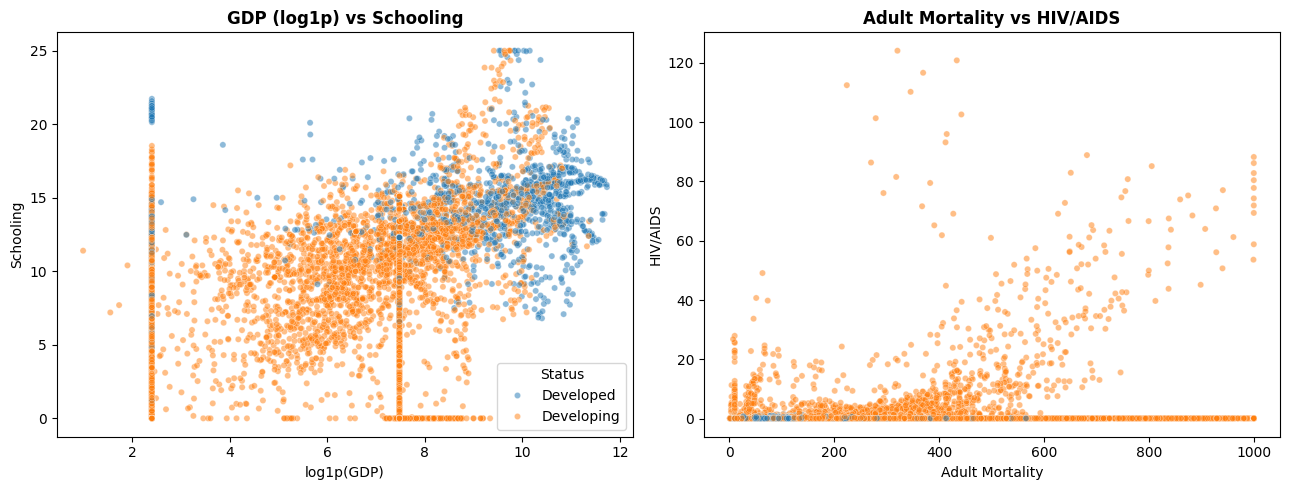

In [ ]:
# Hubungan indikator ekonomi vs pendidikan, dan beban kesehatan
plot_df = train_df.copy()
plot_df["GDP_log"] = np.log1p(plot_df["GDP"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=plot_df,
    x="GDP_log",
    y="Schooling",
    hue="Status",
    alpha=0.5,
    s=20,
    ax=axes[0]
 )
axes[0].set_title("GDP (log1p) vs Schooling", fontweight="bold")
axes[0].set_xlabel("log1p(GDP)")
axes[0].set_ylabel("Schooling")

sns.scatterplot(
    data=plot_df,
    x="Adult Mortality",
    y="HIV/AIDS",
    hue="Status",
    alpha=0.5,
    s=20,
    ax=axes[1]
 )
axes[1].set_title("Adult Mortality vs HIV/AIDS", fontweight="bold")
axes[1].set_xlabel("Adult Mortality")
axes[1].set_ylabel("HIV/AIDS")

if axes[1].legend_:
    axes[1].legend_.remove()

plt.tight_layout()
plt.show()

#### Insight dari Scatter Plot

- GDP (log1p) dan Schooling menunjukkan hubungan positif yang jelas; negara Developed cenderung berada di kuadran kanan atas.
- Adult Mortality dan HIV/AIDS juga bergerak searah, menandakan beban kesehatan yang meningkat bersamaan.
- Walau ada pemisahan kasar antara status, masih banyak titik yang overlap. Ini menguatkan kebutuhan clustering untuk menemukan kelompok yang lebih halus dibanding sekadar status.

# EDA Question:
## Apakah proyeksi indikator kesehatan dan sosio-ekonomi ke 2 dimensi (PCA) menunjukkan pemisahan alami antara negara Developed dan Developing?

Total variance explained by 2 PCs: 37.71%


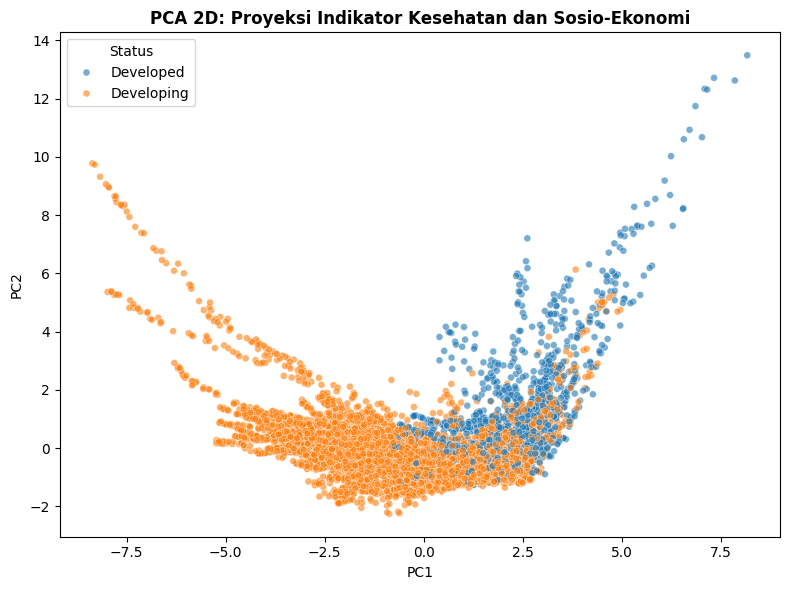

In [ ]:
# PCA 2D untuk melihat pola pemisahan data
feature_cols = [
    "Adult Mortality",
    "infant deaths",
    "HIV/AIDS",
    "Measles",
    "Hepatitis B",
    "Polio",
    "Diphtheria",
    "BMI",
    "thinness  1-19 years",
    "GDP",
    "percentage expenditure",
    "Total expenditure",
    "Schooling",
    "Income composition of resources",
    "Alcohol"
 ]

X_eda = train_df[feature_cols].copy()
X_eda_imputed = SimpleImputer(strategy="median").fit_transform(X_eda)
X_eda_scaled = StandardScaler().fit_transform(X_eda_imputed)

pca = PCA(n_components=2, random_state=42)
X_eda_pca = pca.fit_transform(X_eda_scaled)

print(f"Total variance explained by 2 PCs: {pca.explained_variance_ratio_.sum():.2%}")

eda_pca_df = pd.DataFrame(X_eda_pca, columns=["PC1", "PC2"])
eda_pca_df["Status"] = train_df["Status"].values

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=eda_pca_df,
    x="PC1",
    y="PC2",
    hue="Status",
    alpha=0.6,
    s=25
 )
plt.title("PCA 2D: Proyeksi Indikator Kesehatan dan Sosio-Ekonomi", fontweight="bold")
plt.tight_layout()
plt.show()

### Interpretasi EDA: Analisis PCA 2D pada Status Negara (Developed vs Developing)

Berdasarkan visualisasi proyeksi komponen utama (PCA 2D) di atas, dapat diidentifikasi beberapa pola penting terkait pemisahan alami antara negara *Developed* (maju) dan *Developing* (berkembang):

**1. Pemisahan Alami (Separation) yang Cukup Terlihat, Namun Tidak Sempurna**
* **Pola Utama:** Titik data yang mewakili negara *Developed* (oranye) dan *Developing* (biru) cenderung menempati ruang atau region yang berbeda. Negara *Developed* umumnya mengelompok di sisi **kiri** plot (nilai PC1 negatif), sedangkan negara *Developing* menyebar luas di sisi **kanan** (nilai PC1 positif).
* **Implikasi:** Ini menunjukkan bahwa kombinasi indikator kesehatan dan sosio-ekonomi (15 fitur awal) secara efektif menangkap perbedaan karakteristik fundamental antara kedua status negara tersebut. Sumbu PC1 bertindak sebagai proksi yang kuat untuk tingkat kesejahteraan suatu negara.

**2. Karakteristik Sumbu PC1 sebagai "Sumbu Kesejahteraan"**
* Semakin jauh sebuah titik bergerak ke arah kiri pada sumbu PC1, semakin ia menunjukkan ciri-ciri negara berkembang (misalnya, angka kematian tinggi, penyakit menular tinggi, PDB dan edukasi lebih rendah).
* Sebaliknya, pergerakan ke kanan pada PC1 sangat identik dengan status *Developed* (imunisasi tinggi, PDB tinggi, harapan hidup lebih baik).

**3. Densitas dan Variansi Klaster (Dispersi Data)**
* **Klaster *Developed*:** Terlihat sangat padat ( *dense*) dan mengumpul secara konsisten di area yang sempit. Ini mengindikasikan bahwa negara-negara maju memiliki karakteristik yang relatif seragam dan stabil dalam hal kesehatan publik dan ekonomi.
* **Klaster *Developing*:** Tersebar (*scattered*) sangat luas ke berbagai arah, terutama di sepanjang sumbu PC1 dan PC2. Ini mencerminkan keragaman yang masif di antara negara-negara berkembang—ada negara berkembang yang nyaris menempel dengan batas negara maju (di tengah), dan ada pula yang kondisinya sangat tertinggal (ekstrem kanan). Hal ini cukup sejalan dengan kondisi nyata, di mana jauh lebih banyak negara berkembang dan jumlahnya yang banyak ini mengandung berbagai keragaman kondisi ekonomi dan kesehatan.

**4. Kehadiran Area Tumpang Tindih (Overlap) dan Potensi Outlier**
* Meskipun terpisah, terdapat sedikit tumpang tindih (*overlap*) antara titik biru dan oranye di sekitar nilai PC1 = 0. Hal ini menandakan adanya negara berkembang (*Developing*) yang secara statistik memiliki profil kesehatan dan ekonomi yang sudah menyamai (atau sedang bertransisi menuju) level negara maju (*Developed*).
* Terdapat beberapa titik biru (*Developing*) yang terlempar jauh ke atas (nilai PC2 positif tinggi) atau ke kanan. Ini adalah indikasi kuat adanya pencilan (*outliers*) yang mungkin mewakili negara-negara dengan krisis ekstrem (misalnya akibat wabah masif atau populasi super besar).

**Kesimpulan EDA:**
Pertanyaan mengenai apakah indikator kesehatan dan sosio-ekonomi menunjukkan **pemisahan alami** dapat dijawab: **Tidak Juga**. Indikator tersebut memang cukup menggambarkan tren-tren pengelompokan yang membelah profil negara menjadi dua kelompok utama yang selaras dengan status *Developed* dan *Developing*. Akan tetapi, masih ada kasus overlapping antara kondisi negara maju dan berkembang sehingga butuh pendekatan khusus untuk metode clustering.

## Step 3: Data Cleaning, Data Preprocessing, dan Feature Engineering

In [ ]:
# Ganti data pre-1982 Hepatitis B yang berisi 0 dengan NaN (penyakit belum diujikan pada saat itu)
def ganti_sebelum1982_hepatitis(train_df):
    train_df = train_df.copy()
    for df in [train_df]:
        mask = (df["Year"] < 1982) & (df["Hepatitis B"] == 0)
        df.loc[mask, "Hepatitis B"] = np.nan
    return train_df

train_cleaned = ganti_sebelum1982_hepatitis(train_df)
train_cleaned = train_cleaned.loc[~train_cleaned["Life expectancy"].isna()].reset_index(drop=True)
print(f"Train shape after cleaning: {train_cleaned.shape}")


Train shape after cleaning: (10062, 21)


In [ ]:
def robust_feature_engineering(df):
    df = df.copy()

    # 1. Target Encoding (Aman & beda nama dari teman)
    if "Status" in df.columns:
        df["is_developed_num"] = np.where(df["Status"] == "Developed", 1, 0)

    # 2. Temporal Factor
    if "Year" in df.columns:
        # Mengurangi dengan tahun terkecil jauh lebih stabil daripada Min-Max
        df["year_centered"] = df["Year"] - df["Year"].min()

    # 3. Vax Shield Index
    vax_cols = ["Hepatitis B", "Polio", "Diphtheria"]
    if all(c in df.columns for c in vax_cols):
        # Fill NaN dengan median hanya untuk menghitung rata-rata vaksin
        temp_vax = df[vax_cols].apply(lambda x: x.fillna(x.median()))
        df["vax_coverage_idx"] = temp_vax.mean(axis=1)

    # 4. Nutrition Index (Pengurangan jauh lebih stabil dari Pembagian)
    if "BMI" in df.columns and "thinness  1-19 years" in df.columns:
        # Memisahkan profil nutrisi positif dan negatif
        df["net_nutrition_score"] = df["BMI"] - df["thinness  1-19 years"]

    # 5. Composite Health Risk (Penjumlahan Log, BUKAN Perkalian)
    if "Adult Mortality" in df.columns and "HIV/AIDS" in df.columns:
        # Penjumlahan logaritma setara dengan mengalikan skala tanpa meledakkan variance
        df["health_risk_index"] = np.log1p(df["Adult Mortality"].clip(0)) + np.log1p(df["HIV/AIDS"].clip(0))

    # 6. Log-Transform Normalization
    log_cols = {
        "Measles": "log_measles",
        "under-five deaths": "log_u5_deaths",
        "percentage expenditure": "log_pct_expenditure",
        "Total expenditure": "log_total_exp",
        "Alcohol": "log_alcohol",
        "GDP": "log_gdp",
        "Adult Mortality": "log_adult_mortality",
        "HIV/AIDS": "log_hiv"
    }

    for raw_col, new_col in log_cols.items():
        if raw_col in df.columns:
            df[new_col] = np.log1p(df[raw_col].clip(0))

    # 7. Drop Redundant Cols
    drops = list(log_cols.keys()) + vax_cols + [
        "Population", "thinness 5-9 years", "Year", "infant deaths",
        "thinness  1-19 years", "BMI"
    ]

    for c in drops:
        if c in df.columns:
            df.drop(columns=[c], inplace=True)

    return df

train_fe = robust_feature_engineering(train_cleaned)

FEATURE_COLS = [c for c in train_fe.columns if c not in ["Status", "Life expectancy"]]
X = train_fe[FEATURE_COLS].values
status_labels = train_cleaned["Status"].values

print(f"X Shape: {X.shape} ({len(FEATURE_COLS)} features)")
print(f"Features: {FEATURE_COLS}")

X Shape: (10062, 15) (15 features)
Features: ['Income composition of resources', 'Schooling', 'is_developed_num', 'year_centered', 'vax_coverage_idx', 'net_nutrition_score', 'health_risk_index', 'log_measles', 'log_u5_deaths', 'log_pct_expenditure', 'log_total_exp', 'log_alcohol', 'log_gdp', 'log_adult_mortality', 'log_hiv']


# Step 4: Optuna Hyperparameter Tuning (Hierarchical Clustering)

In [ ]:
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler

# --- FUNGSI HELPER OPTUNA ---, Credit to: Abinaya Fuun
def build_imputer(trial):
    use_knn = trial.suggest_categorical("use_knn", [True, False])
    if use_knn:
        n_neighbors = trial.suggest_int("knn_neighbors", 5, 20)
        return KNNImputer(n_neighbors=n_neighbors)
    else:
        strategy = trial.suggest_categorical("impute_strategy", ["mean", "median"])
        return SimpleImputer(strategy=strategy)

def build_scaler(trial):
    scaler_type = trial.suggest_categorical("scaler", ["standard", "robust"])
    return RobustScaler() if scaler_type == "robust" else StandardScaler()

# --- FUNGSI OBJECTIVE UTAMA ---
def objective(trial):
    # 1. Pipeline Preprocessing Dinamis dari Optuna
    imputer = build_imputer(trial)
    X_imputed = imputer.fit_transform(X)

    scaler = build_scaler(trial)
    X_processed = scaler.fit_transform(X_imputed)

    # 2. Pipeline Clustering Dinamis dari Optuna
    # Telah dioptimasi dari awalnya 2-15 klaster, sekarang hanya 2-7 klaster
    n_clusters = trial.suggest_int('n_clusters', 2, 7)
    linkage = trial.suggest_categorical('linkage', ['ward', 'complete', 'average'])

    model = AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage)
    labels = model.fit_predict(X_processed)

    # Target kita adalah memaksimalkan Silhouette Score
    return silhouette_score(X_processed, labels)

# --- MEMULAI EKSPERIMEN ---
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=25)

print("\nKonfigurasi Terbaik Ditemukan:")
print(f"Silhouette Score Terbaik : {study.best_value:.4f}")
print(f"Parameter Terbaik        : {study.best_params}")

# Menyimpan parameter terbaik ke dalam variabel
best_k = study.best_params['n_clusters']
best_linkage = study.best_params['linkage']
best_scaler_type = study.best_params['scaler']
best_use_knn = study.best_params['use_knn']


Konfigurasi Terbaik Ditemukan:
Silhouette Score Terbaik : 0.7563
Parameter Terbaik        : {'use_knn': True, 'knn_neighbors': 16, 'scaler': 'robust', 'n_clusters': 2, 'linkage': 'average'}


# Step 5: Training the Model

In [ ]:
# 1. Bikin Imputer Terbaik
if best_use_knn:
    best_imputer = KNNImputer(n_neighbors=study.best_params['knn_neighbors'])
else:
    best_imputer = SimpleImputer(strategy=study.best_params['impute_strategy'])

# 2. Bikin Scaler Terbaik
if best_scaler_type == 'robust':
    best_scaler = RobustScaler()
else:
    best_scaler = StandardScaler()

# 3. Terapkan ke data Train & Test
X_train_imputed = best_imputer.fit_transform(X)
X_train_final = best_scaler.fit_transform(X_train_imputed)

# (Ingat: untuk X_test, gunakan .transform() saja, jangan .fit_transform())

# 4. Train Agglomerative model final
final_model = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage)
final_labels = final_model.fit_predict(X_train_final)

# Step 6: Evaluasi dengan Silhouette Score

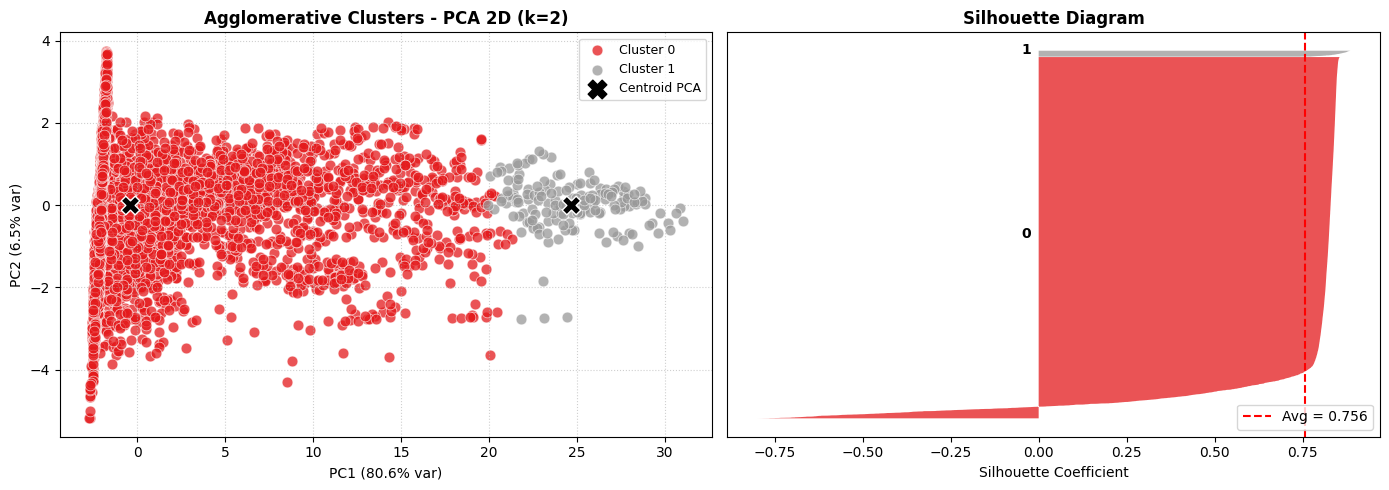

In [ ]:
# Hitung rata-rata Silhouette Score dan skor per sampel
sil = silhouette_score(X_train_final, final_labels)
sil_vals = silhouette_samples(X_train_final, final_labels)

# Jalankan PCA untuk visualisasi 2 Dimensi
pca_2d = PCA(n_components=2, random_state=42)
X_vis = pca_2d.fit_transform(X_train_final)
ev = pca_2d.explained_variance_ratio_

K = best_k

# Handle versi Matplotlib untuk Colormap
try:
    cmap_k = plt.colormaps.get_cmap("Set1").resampled(K)
except AttributeError:
    cmap_k = plt.cm.get_cmap("Set1", K)

# Inisiasi Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# === KIRI: PCA SCATTER ===
for i in range(K):
    mask = final_labels == i
    axes[0].scatter(X_vis[mask, 0], X_vis[mask, 1],
                    color=cmap_k(i), s=60, alpha=0.75,
                    label=f"Cluster {i}", edgecolors='white', linewidth=0.5)

# Tambahkan centroid bayangan (rata-rata koordinat PCA per klaster)
for i in range(K):
    cx = X_vis[final_labels == i, 0].mean()
    cy = X_vis[final_labels == i, 1].mean()
    axes[0].scatter(cx, cy, c="black", s=180, marker="X", zorder=10, edgecolors='white')

axes[0].scatter([], [], c="black", s=180, marker="X", label="Centroid PCA")

axes[0].set_title(f"Agglomerative Clusters - PCA 2D (k={K})", fontweight="bold")
axes[0].set_xlabel(f"PC1 ({ev[0]*100:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({ev[1]*100:.1f}% var)")
axes[0].legend(fontsize=9, loc='best')
axes[0].grid(True, linestyle=':', alpha=0.6)

# === KANAN: SILHOUETTE DIAGRAM ===
y_lower = 10
for i in range(K):
    # Ambil nilai siluet untuk klaster ini dan urutkan
    vals_i = np.sort(sil_vals[final_labels == i])
    y_upper = y_lower + len(vals_i)

    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, vals_i,
                          facecolor=cmap_k(i), alpha=0.75)
    # Tuliskan angka klaster di tengah pisau diagram
    axes[1].text(-0.05, y_lower + len(vals_i) / 2, str(i), fontsize=10, fontweight="bold")

    # Update jarak untuk klaster selanjutnya
    y_lower = y_upper + 10

# Garis batas rata-rata silhouette
axes[1].axvline(sil, color="red", linestyle="--", linewidth=1.5, label=f"Avg = {sil:.3f}")
axes[1].set_title("Silhouette Diagram", fontweight="bold")
axes[1].set_xlabel("Silhouette Coefficient")
axes[1].set_yticks([]) # Hilangkan angka bertumpuk di sumbu Y
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## Interpretasi

Hasil klastering menunjukkan pembagian dua kelompok yang sangat asimetris, dengan Cluster 0 sebagai representasi mayoritas global dan Cluster 1 sebagai kelompok minoritas. Karena tujuannya untuk menentukan kira-kira negara yang dalam kondisi darurat, clustering ini sudah cukup menunjukkannya. Cluster 1 dapat dikatakan teridentifikasi sebagai kelompok rentan yang butuh bantuan/pertolongan dunia. Melihat metrik yang digunakan, mungkin (diasumsikan) klaster tersebut memiliki ciri seperti tingginya beban penyakit (seperti HIV dan mortalitas balita), rendahnya indeks cakupan imunisasi, serta ketertinggalan kapasitas sosio-ekonomi (GDP dan pendidikan). Alhasil, Cluster 1 diposisikan sebagai pusat wilayah krisis yang memerlukan prioritas utama dalam alokasi intervensi bantuan (misalnya, medis atau ekonomi) darurat.

Evaluasi model menghasilkan rata-rata Silhouette Score yang cukup tinggi sebesar 0.756, yang sekilas mengindikasikan struktur pembagian klaster yang kuat. Memang dominan pada cluster 0, tetapi untuk cluster 1, koefisiennya di atas rata-rata. Koefisien minus pada cluster 0 bisa jadi menandakan titik pada perbatasan. Secara interpretasi general, clustering sudah membentuk struktur kuat dan cukup terpisah.

## Step 6: Cluster Profiling dan Distribusi Status

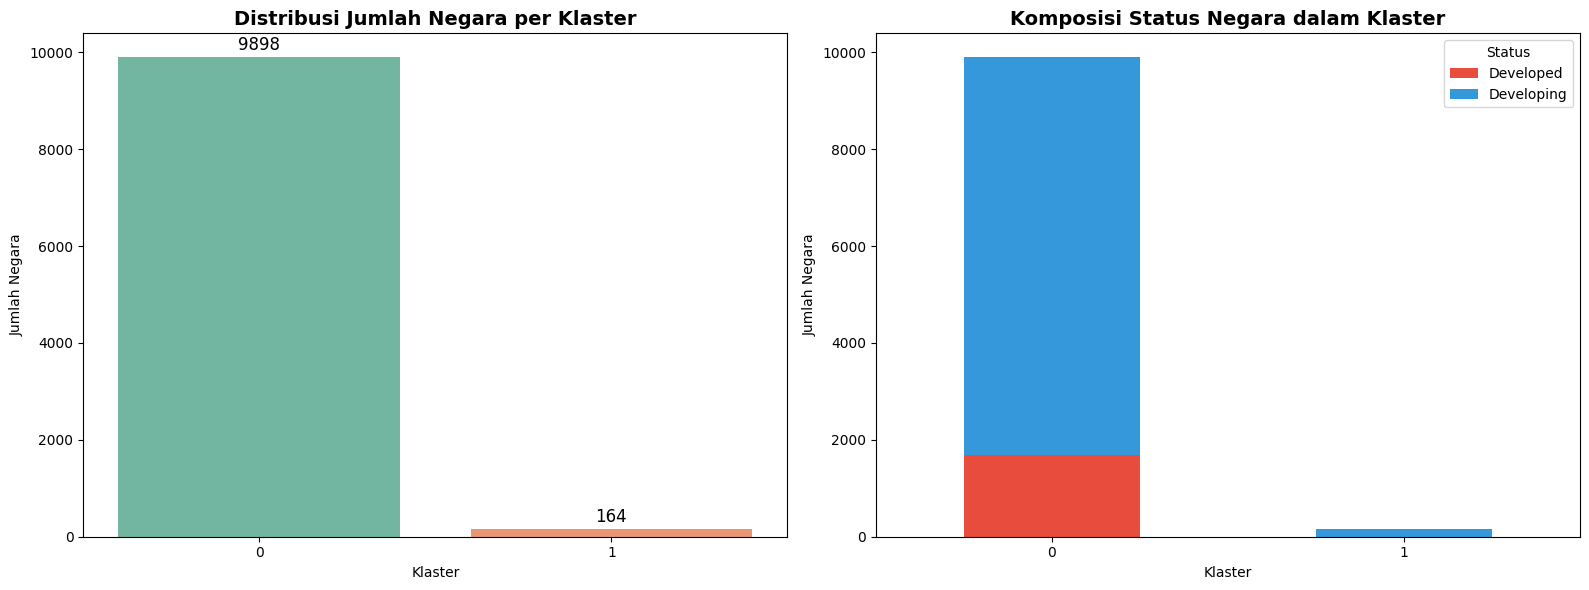

--- Tabel Proporsi Status per Klaster (%) ---


Status,Developed,Developing
Cluster,,
0,17.07,82.93
1,0.00,100.00


--- Tabel Rata-rata Indikator Baru per Klaster ---


,Life expectancy,GDP,Schooling,vax_coverage_idx,net_nutrition_score,health_risk_index
Cluster,,,,,,
0,62.07,4368.71,9.04,70.49,25.17,5.26
1,38.75,580.07,9.30,61.86,8.93,10.26


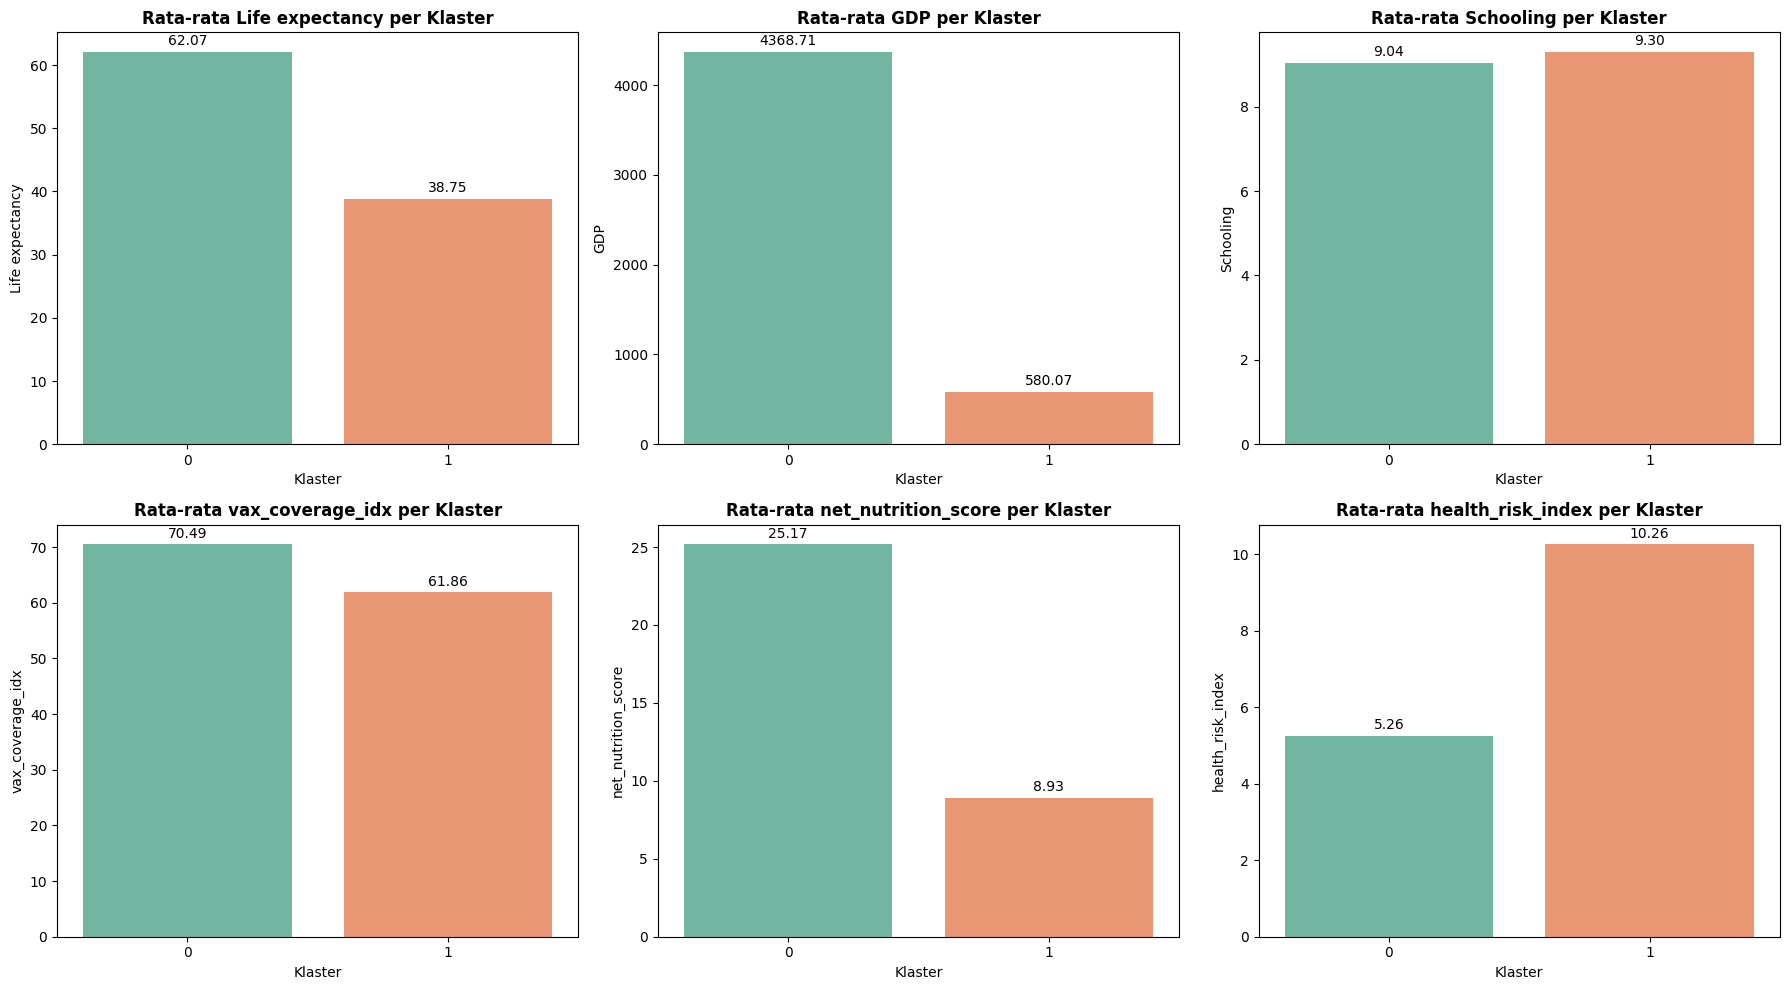

In [ ]:
df_vis = pd.DataFrame({
    'Cluster': final_labels,
    'Status': status_labels  # Menggunakan variabel yang kita perbaiki tadi
})

# 2. Membuat Subplots
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# --- PLOT 1: Total Negara per Klaster ---
sns.countplot(data=df_vis, x='Cluster', palette='Set2', ax=ax[0], hue='Cluster', legend=False)
ax[0].set_title('Distribusi Jumlah Negara per Klaster', fontweight='bold', fontsize=14)
ax[0].set_xlabel('Klaster')
ax[0].set_ylabel('Jumlah Negara')

# Menambahkan label angka di atas bar
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                   ha='center', va='baseline', fontsize=12, color='black', xytext=(0, 5),
                   textcoords='offset points')

# --- PLOT 2: Komposisi Status (Developed/Developing) dalam Klaster ---
# Membuat tabel kontingensi untuk stacked bar
status_cluster = pd.crosstab(df_vis['Cluster'], df_vis['Status'])
status_cluster_pct = status_cluster.div(status_cluster.sum(1), axis=0) * 100

status_cluster.plot(kind='bar', stacked=True, ax=ax[1], color=['#e74c3c', '#3498db'])
ax[1].set_title('Komposisi Status Negara dalam Klaster', fontweight='bold', fontsize=14)
ax[1].set_xlabel('Klaster')
ax[1].set_ylabel('Jumlah Negara')
ax[1].legend(title='Status', loc='upper right')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

# Menampilkan Tabel Proporsi (Angka Persis)
print("--- Tabel Proporsi Status per Klaster (%) ---")
display(status_cluster_pct.round(2))

df_analysis = train_cleaned.copy()

df_analysis['Cluster'] = final_labels

df_analysis['vax_coverage_idx'] = train_fe['vax_coverage_idx']
df_analysis['net_nutrition_score'] = train_fe['net_nutrition_score']
df_analysis['health_risk_index'] = train_fe['health_risk_index']

# Menentukan kolom target baru (Kombinasi makro kesehatan & ekonomi)
target_cols_new = [
    'Life expectancy', 'GDP', 'Schooling',
    'vax_coverage_idx', 'net_nutrition_score', 'health_risk_index'
]

# Validasi otomatis spasi tersembunyi
target_cols_new = [c if c in df_analysis.columns else c + ' ' for c in target_cols_new]

# Menghitung Rata-rata per Klaster
df_summary_new = df_analysis.groupby('Cluster')[target_cols_new].mean()

print("--- Tabel Rata-rata Indikator Baru per Klaster ---")
df_summary_clean_new = df_summary_new.copy()
df_summary_clean_new.columns = [c.strip() for c in df_summary_clean_new.columns]
display(df_summary_clean_new.round(2))
print("\n" + "="*70 + "\n")

# --- VISUALISASI BAR PLOT INDIKATOR BARU ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(target_cols_new):
    sns.barplot(data=df_analysis, x='Cluster', y=col, ax=axes[i], palette='Set2', errorbar=None, hue='Cluster', legend=False)
    axes[i].set_title(f'Rata-rata {col.strip()} per Klaster', fontweight='bold', fontsize=12)
    axes[i].set_xlabel('Klaster')
    axes[i].set_ylabel(col.strip())

    # Menambahkan label angka presisi di atas setiap bar
    for p in axes[i].patches:
        height = p.get_height()
        if not pd.isna(height):
            axes[i].annotate(f'{height:.2f}', (p.get_x() + p.get_width()/2., height),
                               ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                               textcoords='offset points')

plt.tight_layout()
plt.show()

Analisis distribusi menunjukkan perbedaan yang sangat kontras antara kedua kelompok. Klaster 0 merupakan segmen makro yang mendominasi panggung global dengan 9.898 observasi, mencakup seluruh negara Developed dan mayoritas negara Developing. Kelompok stabil ini didukung oleh kapasitas ekonomi yang kuat (rata-rata GDP $4.368,71) serta ketahanan kesehatan yang solid, di mana indeks vaksinasi (vax_coverage_idx: 70,49) dan kecukupan nutrisi (net_nutrition_score: 25,17) berhasil menekan risiko kesehatan makro (health_risk_index: 5,26). Fondasi yang sehat ini secara langsung berkorelasi pada tingginya capaian Angka Harapan Hidup (Life Expectancy) di angka 62,07 tahun.

Sebaliknya, Klaster 1 bertindak sebagai kelompok anomali ekstrem yang sangat eksklusif, hanya mengisolasi 164 observasi negara Developing. Kelompok ini terjebak dalam krisis berbagai sektor yang akut: kelumpuhan finansial dengan GDP yang sangat rendah ($580,07) berpadu dengan kerentanan nutrisi parah (net_nutrition_score: 8,93) serta proteksi imun yang rapuh. Dampak destruktif ini memicu ledakan indeks risiko kesehatan hingga 10,26 akibat tingginya beban epidemiologis HIV/AIDS dan mortalitas dewasa. Hal ini berkorelasi langsung dengan Angka Harapan Hidup di klaster ini. Life expectancy-nya terpangkas drastis menjadi hanya 38,75 tahun, menegaskan status mereka sebagai wilayah krisis kemanusiaan yang terisolasi dari pola umum dunia.

Menariknya, terdapat paradoks di mana durasi sekolah (Schooling) di Klaster 1 sedikit lebih tinggi (9,30 tahun) dibanding Klaster 0 (9,04 tahun). Hal ini membuktikan bahwa modal manusia yang dibangun lewat pendidikan dasar menjadi tidak produktif akibat pendeknya usia harapan hidup. Implikasi strategis bagi lembaga internasional adalah keharusan untuk mengubah pendekatan bantuan: investasi di Klaster 1 wajib dialihkan dari program umum atau pendidikan makro, langsung menuju intervensi medis darurat spesifik (distribusi pangan therapeutic, kampanye imunisasi, dan obat ARV massal) sebagai kunci utama (enabler) sebelum membenahi roda ekonomi.